<a href="https://colab.research.google.com/github/zulfaymyself/zulfaymyself/blob/main/GCI_2026_Finalsub.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Final Assignment Tutorial — Telecom

This notebook is a reference walkthrough for the GCI World 2026 Winter final assignment.
The dataset comes from **Company A**, an anonymous telecommunications service provider, and contains historical customer information across two linked tables (`Client.csv`, `Record.csv`).

Your task is to analyze this data, build a machine learning model whose output supports a concrete business proposal — not to build the best possible model.

**What this notebook walks through:**
1. Market context.
2. Loading and merging the two source tables.
3. EDA: shape, missingness, target distribution, and a worked feature example.
4. Problem Definition — choosing the target and the ML task.
5. Preprocessing — what EDA told us we have to do.
6. A baseline churn classifier.
7. Model evaluation and feature importance.
8. From model to business proposal.

> **Treat this as a reference, not a template.** The strongest submissions diverge from it: a different target, a different segment, a different lever. Originality is rewarded.


---

## 1.Introduction & Market Analysis


### 1.1 Company context
*Company A* is a wireless telecommunications operator. They have years of usage and billing data on roughly 100,000 customers but no in-house machine learning capability.

When a company commissions a business proposal, they usually arrive with a vague sense that *something* needs to improve — margins, retention, growth, customer satisfaction — but no clear view of which lever to pull, which segment to focus on, or even which question to start with. **Choosing the question is the analyst's first job, and the rest of the proposal stands or falls on it.** The dataset rarely points to a single obvious answer; it admits several, and which one you pursue determines the kind of recommendation you can make.

This dataset includes a binary `churn` flag — whether a customer left within 31–60 days after the observation date — and we use churn as the worked example throughout this notebook. But churn is one of many viable targets the data supports. **You may and should explore other targets** — revenue, usage, equipment lifecycle, segment-level behaviour. Pick the question whose answer best supports the proposal you want to make.

### 1.2 Why this market matters
- Acquiring a new subscriber costs several times more than keeping one — retention, usage, and ARPU all translate directly into margin.
- Mature, saturated markets grow by taking customers from competitors or lifting revenue per existing customer.
- Behaviour signals (usage decline, complaints, equipment ageing) precede both churn and revenue compression by months.

**Questions to think about:**
- What does the telecom market look like in your country or region — who are the major players, what local dynamics (regulation, technology shifts, new entrants) are reshaping churn, and what story can you tell about a specific market you know? A proposal grounded in a local market you can describe concretely is more compelling than one assembled from generic global figures.
- What recent, citable sources can you find that quantify these claims for your target market? Uncited industry numbers will not strengthen your case.
- What share of churn in this market is voluntary (customer-initiated) versus involuntary (non-payment, address change)? Which one can a model meaningfully address?

### 1.3 **RECOVERY CELL**

The recovery cell restores the important datasets, variables, group comparisons, and summary tables. It does not redraw all eight earlier graphs, because those plots are already documented in the notebook and do not need to be regenerated just to continue coding.

In [10]:
# RECOVERY CELL - CHECKPOINT: EDA COMPLETED

# 1. IMPORT LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import drive

pd.set_option("display.max_columns", 120)

# 2. CONNECT GOOGLE DRIVE
drive.mount("/content/drive")

# 3. DEFINE DATASET PATHS
current_dir = Path("/content/drive/MyDrive")

client_path = current_dir / "telecom" / "Client.csv"
record_path = current_dir / "telecom" / "Record.csv"

assert client_path.is_file(), "Client.csv not found!"
assert record_path.is_file(), "Record.csv not found!"

# 4. LOAD DATASETS
client = pd.read_csv(client_path)
record = pd.read_csv(record_path)

# 5. VERIFY CUSTOMER IDS
assert client["Customer_ID"].is_unique
assert record["Customer_ID"].is_unique
assert client["Customer_ID"].notna().all()
assert record["Customer_ID"].notna().all()

# 6. MERGE DATASETS
df = record.merge(
    client,
    on="Customer_ID",
    how="inner",
    validate="one_to_one"
)

assert df.shape == (100000, 100)
assert df["churn"].notna().all()

# 7. RESTORE DATA QUALITY ANALYSIS
client_missing = client.isnull().mean() * 100
record_missing = record.isnull().mean() * 100

# 8. RESTORE CHURN DISTRIBUTION
churn_counts = df["churn"].value_counts().sort_index()

churn_percentages = (
    df["churn"].value_counts(normalize=True).sort_index() * 100
)

# 9. RESTORE NUMERICAL FEATURE COMPARISON
features = [
    "rev_Mean",
    "mou_Mean",
    "change_mou",
    "custcare_Mean",
    "eqpdays",
    "months"
]

comparison = df.groupby("churn")[features].median()

# 10. RESTORE HANDSET AGE ANALYSIS
age_df = df[
    df["eqpdays"].notna() &
    (df["eqpdays"] >= 0)
].copy()

age_df["age_group"] = pd.cut(
    age_df["eqpdays"],
    bins=[-0.001, 180, 365, 730, float("inf")],
    labels=[
        "0-180 days",
        "181-365 days",
        "366-730 days",
        "Over 730 days"
    ]
)

age_summary = age_df.groupby(
    "age_group", observed=True
)["churn"].agg(
    customers="count",
    churn_rate="mean"
).reset_index()

age_summary["churn_rate"] *= 100

# 11. RESTORE USAGE CHANGE ANALYSIS
usage_df = df.dropna(subset=["change_mou"]).copy()

usage_df["usage_group"] = pd.qcut(
    usage_df["change_mou"],
    q=4,
    duplicates="drop"
)

usage_summary = usage_df.groupby(
    "usage_group", observed=True
)["churn"].agg(
    customers="count",
    churn_rate="mean"
).reset_index()

usage_summary["churn_rate"] *= 100

# 12. RESTORE COMBINED RISK ANALYSIS
risk_df = df[
    df["eqpdays"].notna() &
    (df["eqpdays"] >= 0) &
    df["change_mou"].notna()
].copy()

risk_df["handset_group"] = np.where(
    risk_df["eqpdays"] > 365,
    "Older handset",
    "Newer handset"
)

risk_df["usage_trend"] = np.where(
    risk_df["change_mou"] < 0,
    "Declining usage",
    "Stable/increasing usage"
)

risk_summary = risk_df.groupby(
    ["handset_group", "usage_trend"]
)["churn"].agg(
    customers="count",
    churn_rate="mean"
).reset_index()

risk_summary["churn_rate"] *= 100

# 13. RESTORE CUSTOMER CARE ANALYSIS
care_df = df.copy()

care_df["care_group"] = pd.cut(
    care_df["custcare_Mean"],
    bins=[-0.001, 0, 1, 3, float("inf")],
    labels=[
        "No calls",
        "More than 0 to 1",
        "More than 1 to 3",
        "More than 3"
    ]
)

care_summary = care_df.groupby(
    "care_group", observed=True
)["churn"].agg(
    customers="count",
    churn_rate="mean"
).reset_index()

care_summary["churn_rate"] *= 100

# 14. RESTORE NETWORK FAILURE ANALYSIS
network_df = df.copy()

network_df["failure_rate"] = np.where(
    network_df["attempt_Mean"] > 0,
    network_df["drop_blk_Mean"] / network_df["attempt_Mean"],
    np.nan
)

network_df = network_df[
    network_df["failure_rate"].between(0, 1)
].copy()

network_df["failure_group"] = pd.cut(
    network_df["failure_rate"],
    bins=[-0.001, 0.01, 0.05, 0.10, 1.0],
    labels=["0-1%", ">1-5%", ">5-10%", ">10%"]
)

network_summary = network_df.groupby(
    "failure_group", observed=True
)["churn"].agg(
    customers="count",
    churn_rate="mean"
).reset_index()

network_summary["churn_rate"] *= 100

# 15. RESTORE REVENUE ANALYSIS
revenue_df = df.dropna(subset=["rev_Mean"]).copy()

revenue_df["revenue_group"] = pd.qcut(
    revenue_df["rev_Mean"],
    q=4,
    duplicates="drop"
)

revenue_summary = revenue_df.groupby(
    "revenue_group", observed=True
).agg(
    customers=("churn", "count"),
    median_revenue=("rev_Mean", "median"),
    churn_rate=("churn", "mean")
).reset_index()

revenue_summary["churn_rate"] *= 100

# 16. RESTORE BUSINESS SEGMENT ANALYSIS
business_df = df[
    df["eqpdays"].notna() &
    (df["eqpdays"] >= 0) &
    df["change_mou"].notna() &
    df["rev_Mean"].notna() &
    (df["rev_Mean"] >= 0)
].copy()

business_df["risk_group"] = np.where(
    (business_df["eqpdays"] > 365) &
    (business_df["change_mou"] < 0),
    "Older handset + declining usage",
    "Other customers"
)

revenue_threshold = business_df["rev_Mean"].quantile(0.75)

business_df["revenue_level"] = np.where(
    business_df["rev_Mean"] >= revenue_threshold,
    "High revenue",
    "Other revenue"
)

business_summary = business_df.groupby(
    ["risk_group", "revenue_level"]
).agg(
    customers=("churn", "count"),
    churn_rate=("churn", "mean"),
    median_revenue=("rev_Mean", "median")
).reset_index()

business_summary["churn_rate"] *= 100

# 17. RESTORE HIGH REVENUE COMPARISON
high_revenue = business_summary[
    business_summary["revenue_level"] == "High revenue"
].copy()

high_revenue["segment"] = high_revenue["risk_group"].map({
    "Older handset + declining usage":
        "Older Handset +\nDeclining Usage",
    "Other customers":
        "Other High-Revenue\nCustomers"
})

# 18. FINAL RECOVERY VERIFICATION
print("=" * 60)
print("GCI WORLD 2026 - PROJECT RECOVERY")
print("=" * 60)

print("Client:", client.shape)
print("Record:", record.shape)
print("Merged:", df.shape)

print("Churn counts:")
print(churn_counts)

print("Business analysis customers:", len(business_df))
print("EDA summaries restored successfully.")

print("=" * 60)
print("RECOVERY COMPLETE - READY TO CONTINUE!")
print("=" * 60)


# RECOVERY CHECKPOINT 2
# RESTORE DATA SPLITTING AND FINAL PREPROCESSING
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# 1. Restore features and target
X = df.drop(columns=["Customer_ID", "churn"]).copy()
y = df["churn"].copy()

# 2. Restore train, validation and test splits
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# 3. Restore feature exclusions
demographic_features = [
    "ethnic", "marital", "income", "adults",
    "kid0_2", "kid3_5", "kid6_10",
    "kid11_15", "kid16_17",
    "ownrent", "lor", "dwlltype",
    "dwllsize", "HHstatin",
    "prizm_social_one", "infobase",
    "numbcars", "creditcd",
    "area", "crclscod"
]

existing_demographic = [
    col for col in demographic_features
    if col in X.columns
]

selected_features = [
    col for col in X.columns
    if col not in existing_demographic
]

# 4. Restore selected datasets
X_train_selected = X_train[selected_features].copy()
X_val_selected = X_val[selected_features].copy()
X_test_selected = X_test[selected_features].copy()

# 5. Identify feature types
numerical_cols_selected = (
    X_train_selected.select_dtypes(
        include=["number"]
    ).columns.tolist()
)

categorical_cols_selected = (
    X_train_selected.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()
)

# 6. Restore preprocessing pipelines
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_cols_selected),
        ("cat", categorical_pipeline, categorical_cols_selected)
    ],
    sparse_threshold=1.0
)

# 7. Fit only on training data
X_train_processed = preprocessor.fit_transform(
    X_train_selected
)

X_val_processed = preprocessor.transform(
    X_val_selected
)

X_test_processed = preprocessor.transform(
    X_test_selected
)

# 8. Verify recovery
assert len(selected_features) == 78
assert X_train_processed.shape[0] == 70000
assert X_val_processed.shape[0] == 15000
assert X_test_processed.shape[0] == 15000

assert (
    X_train_processed.shape[1]
    == X_val_processed.shape[1]
    == X_test_processed.shape[1]
)

print("\n" + "=" * 60)
print("GCI FINAL ASSIGNMENT - RECOVERY CHECKPOINT 2")
print("=" * 60)

print("Original features:", X.shape[1])
print("Selected features:", len(selected_features))
print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)

print("\nRECOVERY CHECKPOINT 2 COMPLETE!")
print("READY FOR XGBOOST MODEL TRAINING.")
print("=" * 60)



# RECOVERY CHECKPOINT 3
# RESTORE SAVED XGBOOST MODEL AND FITTED PREPROCESSOR
# ============================================================

from pathlib import Path
import json
import joblib
import numpy as np
from xgboost import XGBClassifier

print("\n" + "=" * 60)
print("GCI FINAL ASSIGNMENT - RECOVERY CHECKPOINT 3")
print("=" * 60)

# 1. Locate saved model files in Google Drive
model_dir = Path(
    "/content/drive/MyDrive/telecom/model_artifacts"
)

model_path = model_dir / "xgboost_churn_baseline.json"
preprocessor_path = model_dir / "preprocessor.joblib"
config_path = model_dir / "model_config.json"

# 2. Verify that all saved files exist
for path in [model_path, preprocessor_path, config_path]:
    assert path.is_file(), f"Missing recovery file: {path}"

print("All model artifact files found: True")

# 3. Restore saved model configuration
with open(config_path, "r") as f:
    model_config = json.load(f)

# Verify feature selection matches the saved model
assert selected_features == model_config["selected_features"], (
    "Selected features do not match saved model configuration!"
)

print("Feature configuration verified: True")

# 4. Restore the fitted preprocessor
preprocessor = joblib.load(preprocessor_path)

print("Saved preprocessor restored: True")

# 5. Recreate processed data using saved preprocessing
X_train_processed = preprocessor.transform(
    X_train_selected
)

X_val_processed = preprocessor.transform(
    X_val_selected
)

X_test_processed = preprocessor.transform(
    X_test_selected
)

# 6. Restore trained XGBoost model
xgb_model = XGBClassifier()

xgb_model.load_model(
    str(model_path)
)

print("Trained XGBoost model restored: True")

# 7. Validate restored feature dimensions
expected_features = model_config["encoded_feature_count"]

assert X_train_processed.shape[1] == expected_features
assert X_val_processed.shape[1] == expected_features
assert X_test_processed.shape[1] == expected_features

assert xgb_model.n_features_in_ == expected_features

# 8. Test model predictions
sample_predictions = xgb_model.predict_proba(
    X_val_processed[:100]
)[:, 1]

assert len(sample_predictions) == 100
assert np.isfinite(sample_predictions).all()
assert (
    (sample_predictions >= 0)
    & (sample_predictions <= 1)
).all()

print("\n===== RESTORED MODEL INFORMATION =====")
print("Model:", model_config["model"])
print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)
print("Testing shape:", X_test_processed.shape)
print("Best iteration:", xgb_model.best_iteration)

print(
    "Saved validation ROC-AUC:",
    round(model_config["validation_roc_auc"], 4)
)

print("Prediction test passed: True")

print("\n" + "=" * 60)
print("RECOVERY CHECKPOINT 3 COMPLETED SUCCESSFULLY!")
print("XGBOOST MODEL READY FOR SECTION 7 EVALUATION.")
print("=" * 60)



# ============================================================
# RECOVERY CHECKPOINT 4
# EVALUATION, TARGETING AND FEATURE IMPORTANCE
# ============================================================

import json
import numpy as np
import pandas as pd

from pathlib import Path

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("\n" + "=" * 60)
print("GCI FINAL ASSIGNMENT - RECOVERY CHECKPOINT 4")
print("=" * 60)

# ------------------------------------------------------------
# 1. Restore model evaluation predictions
# ------------------------------------------------------------

y_test_prob = xgb_model.predict_proba(
    X_test_processed
)[:, 1]

threshold = 0.50

y_test_pred = (
    y_test_prob >= threshold
).astype(int)

# ------------------------------------------------------------
# 2. Restore test evaluation metrics
# ------------------------------------------------------------

test_auc = roc_auc_score(
    y_test, y_test_prob
)

test_accuracy = accuracy_score(
    y_test, y_test_pred
)

test_precision = precision_score(
    y_test, y_test_pred,
    zero_division=0
)

test_recall = recall_score(
    y_test, y_test_pred,
    zero_division=0
)

test_f1 = f1_score(
    y_test, y_test_pred,
    zero_division=0
)

cm = confusion_matrix(
    y_test, y_test_pred,
    labels=[0, 1]
)

print("\n===== RESTORED EVALUATION RESULTS =====")

print(f"Test ROC-AUC: {test_auc:.4f}")
print(f"Accuracy: {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall: {test_recall:.4f}")
print(f"F1-score: {test_f1:.4f}")

print("\nConfusion matrix:")
print(cm)

# ------------------------------------------------------------
# 3. Restore targeting and lift analysis
# ------------------------------------------------------------

actual_churn = np.asarray(y_test)
risk_scores = np.asarray(y_test_prob)

ranked_indices = np.argsort(
    -risk_scores,
    kind="stable"
)

overall_churn_rate = actual_churn.mean()
total_churners = int(actual_churn.sum())

results = []

for target_share in [0.10, 0.20, 0.30]:

    n_targeted = int(
        len(actual_churn) * target_share
    )

    top_indices = ranked_indices[:n_targeted]

    churners_found = int(
        actual_churn[top_indices].sum()
    )

    targeted_churn_rate = (
        churners_found / n_targeted
    )

    lift = (
        targeted_churn_rate / overall_churn_rate
    )

    capture_rate = (
        churners_found / total_churners
    )

    results.append({
        "Targeted customers": n_targeted,
        "Target share": f"{target_share:.0%}",
        "Actual churners found": churners_found,
        "Churn rate in group": round(
            targeted_churn_rate, 4
        ),
        "Lift": round(lift, 3),
        "Churners captured": round(
            capture_rate, 4
        )
    })

targeting_results = pd.DataFrame(results)

print("\n===== RESTORED TARGETING RESULTS =====")

print(
    targeting_results.to_string(index=False)
)

# ------------------------------------------------------------
# 4. Restore feature importance results
# ------------------------------------------------------------

output_dir = Path(
    "/content/drive/MyDrive/telecom/model_artifacts"
)

feature_path = (
    output_dir / "section_7_1_feature_importance.csv"
)

assert feature_path.is_file(), (
    "Feature importance CSV not found!"
)

feature_importance_df = pd.read_csv(
    feature_path
)

top_15_features = feature_importance_df.head(15)

assert len(feature_importance_df) == 90, (
    "Unexpected number of encoded features!"
)

print("\n===== RESTORED TOP 5 FEATURES =====")

print(
    feature_importance_df[
        ["Feature", "Gain"]
    ].head(5).to_string(index=False)
)

# ------------------------------------------------------------
# 5. Save evaluation results
# ------------------------------------------------------------

evaluation_summary = {
    "model": "XGBoostClassifier",
    "test_customers": int(len(y_test)),
    "classification_threshold": threshold,
    "validation_roc_auc": float(
        model_config["validation_roc_auc"]
    ),
    "test_roc_auc": float(test_auc),
    "accuracy": float(test_accuracy),
    "precision": float(test_precision),
    "recall": float(test_recall),
    "f1_score": float(test_f1),
    "confusion_matrix": cm.tolist(),
    "overall_test_churn_rate": float(
        overall_churn_rate
    )
}

evaluation_path = (
    output_dir / "section_7_evaluation_results.json"
)

with open(evaluation_path, "w") as f:
    json.dump(
        evaluation_summary,
        f,
        indent=4
    )

targeting_path = (
    output_dir / "section_7_targeting_results.csv"
)

targeting_results.to_csv(
    targeting_path,
    index=False
)

# ------------------------------------------------------------
# 6. Verify recovered results
# ------------------------------------------------------------

assert len(y_test_prob) == 15000
assert np.isfinite(y_test_prob).all()
assert cm.sum() == 15000
assert len(targeting_results) == 3

assert np.isclose(
    test_auc, 0.6862, atol=0.001
), "Test ROC-AUC differs from verified result!"

assert np.isclose(
    test_accuracy, 0.6326, atol=0.001
), "Accuracy differs from verified result!"

assert np.isclose(
    targeting_results.loc[0, "Lift"],
    1.593,
    atol=0.001
), "Targeting lift differs from verified result!"

print("\n===== SAVED RECOVERY FILES =====")

print(
    "Evaluation results:",
    evaluation_path.is_file()
)

print(
    "Targeting results:",
    targeting_path.is_file()
)

print(
    "Feature importance:",
    feature_path.is_file()
)

print("\n" + "=" * 60)
print("RECOVERY CHECKPOINT 4 COMPLETED SUCCESSFULLY!")
print("READY FOR SECTION 8 - FROM MODEL TO PROPOSAL")
print("=" * 60)



# ============================================================
# RECOVERY CHECKPOINT 5
# RESTORE SECTION 8 BUSINESS AND FINANCIAL ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import json
from pathlib import Path

print("\n" + "=" * 60)
print("GCI FINAL ASSIGNMENT - RECOVERY CHECKPOINT 5")
print("=" * 60)

# ------------------------------------------------------------
# 1. Locate saved Section 8 files
# ------------------------------------------------------------

output_dir = Path(
    "/content/drive/MyDrive/telecom/model_artifacts"
)

financial_path = (
    output_dir / "section_8_financial_scenarios.csv"
)

break_even_path = (
    output_dir / "section_8_break_even.csv"
)

sample_size_path = (
    output_dir / "section_8_pilot_sample_size.csv"
)

required_files = [
    financial_path,
    break_even_path,
    sample_size_path
]

for path in required_files:
    assert path.is_file(), f"Missing recovery file: {path}"

print("All Section 8 analysis files found: True")

# ------------------------------------------------------------
# 2. Rebuild Section 8.1 customer revenue analysis
# ------------------------------------------------------------

business_df = pd.DataFrame({
    "risk_score": np.asarray(y_test_prob),
    "actual_churn": np.asarray(y_test),
    "revenue": pd.to_numeric(
        X_test["rev_Mean"],
        errors="coerce"
    ).to_numpy()
})

business_df = (
    business_df
    .sort_values(
        "risk_score",
        ascending=False,
        kind="stable"
    )
    .reset_index(drop=True)
)

top_10_count = int(len(business_df) * 0.10)

business_df["high_risk"] = False

business_df.loc[
    :top_10_count - 1,
    "high_risk"
] = True

high_revenue_threshold = float(
    X_train["rev_Mean"].quantile(0.75)
)

business_df["high_revenue"] = (
    business_df["revenue"]
    >= high_revenue_threshold
)

high_risk_high_value = business_df[
    business_df["high_risk"]
    & business_df["high_revenue"]
].copy()

risk_summary = business_df.groupby(
    "high_risk"
).agg(
    customers=("actual_churn", "size"),
    churn_rate=("actual_churn", "mean"),
    average_revenue=("revenue", "mean"),
    median_revenue=("revenue", "median")
)

print("\n===== RESTORED REVENUE ANALYSIS =====")

print("Test customers:", len(business_df))
print("Highest-risk customers:", top_10_count)

print(
    "High-risk, high-revenue customers:",
    len(high_risk_high_value)
)

print(
    "High-revenue threshold:",
    round(high_revenue_threshold, 2)
)

print(
    "High-risk, high-revenue churn rate:",
    f"{high_risk_high_value['actual_churn'].mean():.2%}"
)

print(
    "High-risk, high-revenue average revenue:",
    round(high_risk_high_value["revenue"].mean(), 2)
)

# ------------------------------------------------------------
# 3. Restore financial-analysis assumptions
# ------------------------------------------------------------

cost_per_customer = 5.0
contribution_margin = 0.40
revenue_periods = 3

churn_reductions = [0.03, 0.05, 0.10]

valid_revenue = business_df["revenue"].where(
    business_df["revenue"] >= 0
)

segments = {
    "Top 10% risk": business_df["high_risk"],

    "High risk + high revenue": (
        business_df["high_risk"]
        & business_df["high_revenue"]
    )
}

# ------------------------------------------------------------
# 4. Restore saved financial scenario results
# ------------------------------------------------------------

financial_df = pd.read_csv(financial_path)

print("\n===== RESTORED FINANCIAL SCENARIOS =====")
print(financial_df.to_string(index=False))

# ------------------------------------------------------------
# 5. Restore saved break-even analysis
# ------------------------------------------------------------

break_even_df = pd.read_csv(break_even_path)

print("\n===== RESTORED BREAK-EVEN RESULTS =====")
print(break_even_df.to_string(index=False))

# ------------------------------------------------------------
# 6. Restore saved pilot sample-size results
# ------------------------------------------------------------

sample_size_df = pd.read_csv(sample_size_path)

print("\n===== RESTORED PILOT SAMPLE SIZES =====")
print(sample_size_df.to_string(index=False))

# ------------------------------------------------------------
# 7. Verify consistency with completed analysis
# ------------------------------------------------------------

assert len(business_df) == 15000
assert top_10_count == 1500

assert len(high_risk_high_value) == 312, (
    "High-risk, high-revenue count differs!"
)

assert np.isclose(
    high_risk_high_value["actual_churn"].mean(),
    0.7436,
    atol=0.001
), "High-risk segment churn rate differs!"

assert len(financial_df) == 6
assert len(break_even_df) == 2
assert len(sample_size_df) == 3

# Check the saved 5-percentage-point financial scenario
scenario_5pp = financial_df.loc[
    (financial_df["Segment"] == "High risk + high revenue")
    & (financial_df["Churn reduction"] == "5% pp")
]

assert len(scenario_5pp) == 1

assert np.isclose(
    float(scenario_5pp["Net benefit"].iloc[0]),
    530.98,
    atol=0.1
), "Financial scenario differs from verified results!"

# Check saved break-even result
selected_break_even = break_even_df.loc[
    break_even_df["Segment"] == "High risk + high revenue",
    "Break-even reduction (pp)"
].iloc[0]

assert np.isclose(
    selected_break_even,
    3.73,
    atol=0.02
), "Break-even result differs!"

# ------------------------------------------------------------
# 8. Save compact business summary
# ------------------------------------------------------------

business_summary = {
    "test_customers": int(len(business_df)),
    "high_risk_customers": int(top_10_count),

    "high_risk_high_revenue_customers": int(
        len(high_risk_high_value)
    ),

    "high_revenue_threshold": float(
        high_revenue_threshold
    ),

    "target_segment_churn_rate": float(
        high_risk_high_value["actual_churn"].mean()
    ),

    "target_segment_average_revenue": float(
        high_risk_high_value["revenue"].mean()
    ),

    "illustrative_cost_per_customer": cost_per_customer,
    "illustrative_contribution_margin": contribution_margin,
    "illustrative_revenue_periods": revenue_periods,

    "financial_assumptions_verified": False,
    "revenue_currency_confirmed": False
}

business_summary_path = (
    output_dir / "section_8_business_summary.json"
)

with open(business_summary_path, "w") as f:
    json.dump(business_summary, f, indent=4)

print("\n===== RECOVERY VERIFICATION =====")

print("Customer segmentation restored: True")
print("Financial scenarios restored: True")
print("Break-even analysis restored: True")
print("Pilot sample-size analysis restored: True")

print(
    "Business summary saved:",
    business_summary_path.is_file()
)

print("\n" + "=" * 60)
print("RECOVERY CHECKPOINT 5 COMPLETED SUCCESSFULLY!")
print("READY FOR SECTION 9 - CONCLUSION")
print("=" * 60)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GCI WORLD 2026 - PROJECT RECOVERY
Client: (100000, 50)
Record: (100000, 51)
Merged: (100000, 100)
Churn counts:
churn
0    50438
1    49562
Name: count, dtype: int64
Business analysis customers: 98973
EDA summaries restored successfully.
RECOVERY COMPLETE - READY TO CONTINUE!

GCI FINAL ASSIGNMENT - RECOVERY CHECKPOINT 2
Original features: 98
Selected features: 78
Training: (70000, 90)
Validation: (15000, 90)
Testing: (15000, 90)

RECOVERY CHECKPOINT 2 COMPLETE!
READY FOR XGBOOST MODEL TRAINING.

GCI FINAL ASSIGNMENT - RECOVERY CHECKPOINT 3
All model artifact files found: True
Feature configuration verified: True
Saved preprocessor restored: True
Trained XGBoost model restored: True

===== RESTORED MODEL INFORMATION =====
Model: XGBoostClassifier
Training shape: (70000, 90)
Validation shape: (15000, 90)
Testing shape: (15000, 90)
Best iteration: 218
Saved val

---

## 2.Setup and Data Loading


### 2.1 Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

from xgboost import XGBClassifier, plot_importance

pd.set_option("display.max_columns", 120)


### 2.2 Connect to Google Drive

If you are running this notebook on Google Colab, mount your Drive and `cd` into the folder that contains the dataset.


In [ ]:
# Run this cell only on Google Colab.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**IMPORTANT**:<br>
Change the path in the `%cd` command below to match the folder where this notebook is saved on Google Drive by **replacing "WhereThisNotebookIsLocated" with your actual folder path**.

Example:
- You uploaded `Final Assignment` folder directly under MyDrive (the default folder when you open Google Drive)
    - Change to "/<wbr>content/drive/MyDrive/Final Assignment"

You can easily locate your notebook's directory by:
1. Open the Files panel on the left side of Colab
2. Navigate through the "drive" and "MyDrive" folders until you find your notebook's folders
3. Click the more actions icon (three vertical dots, $\vdots$) next to the folder name
4. Select the option "Copy path"

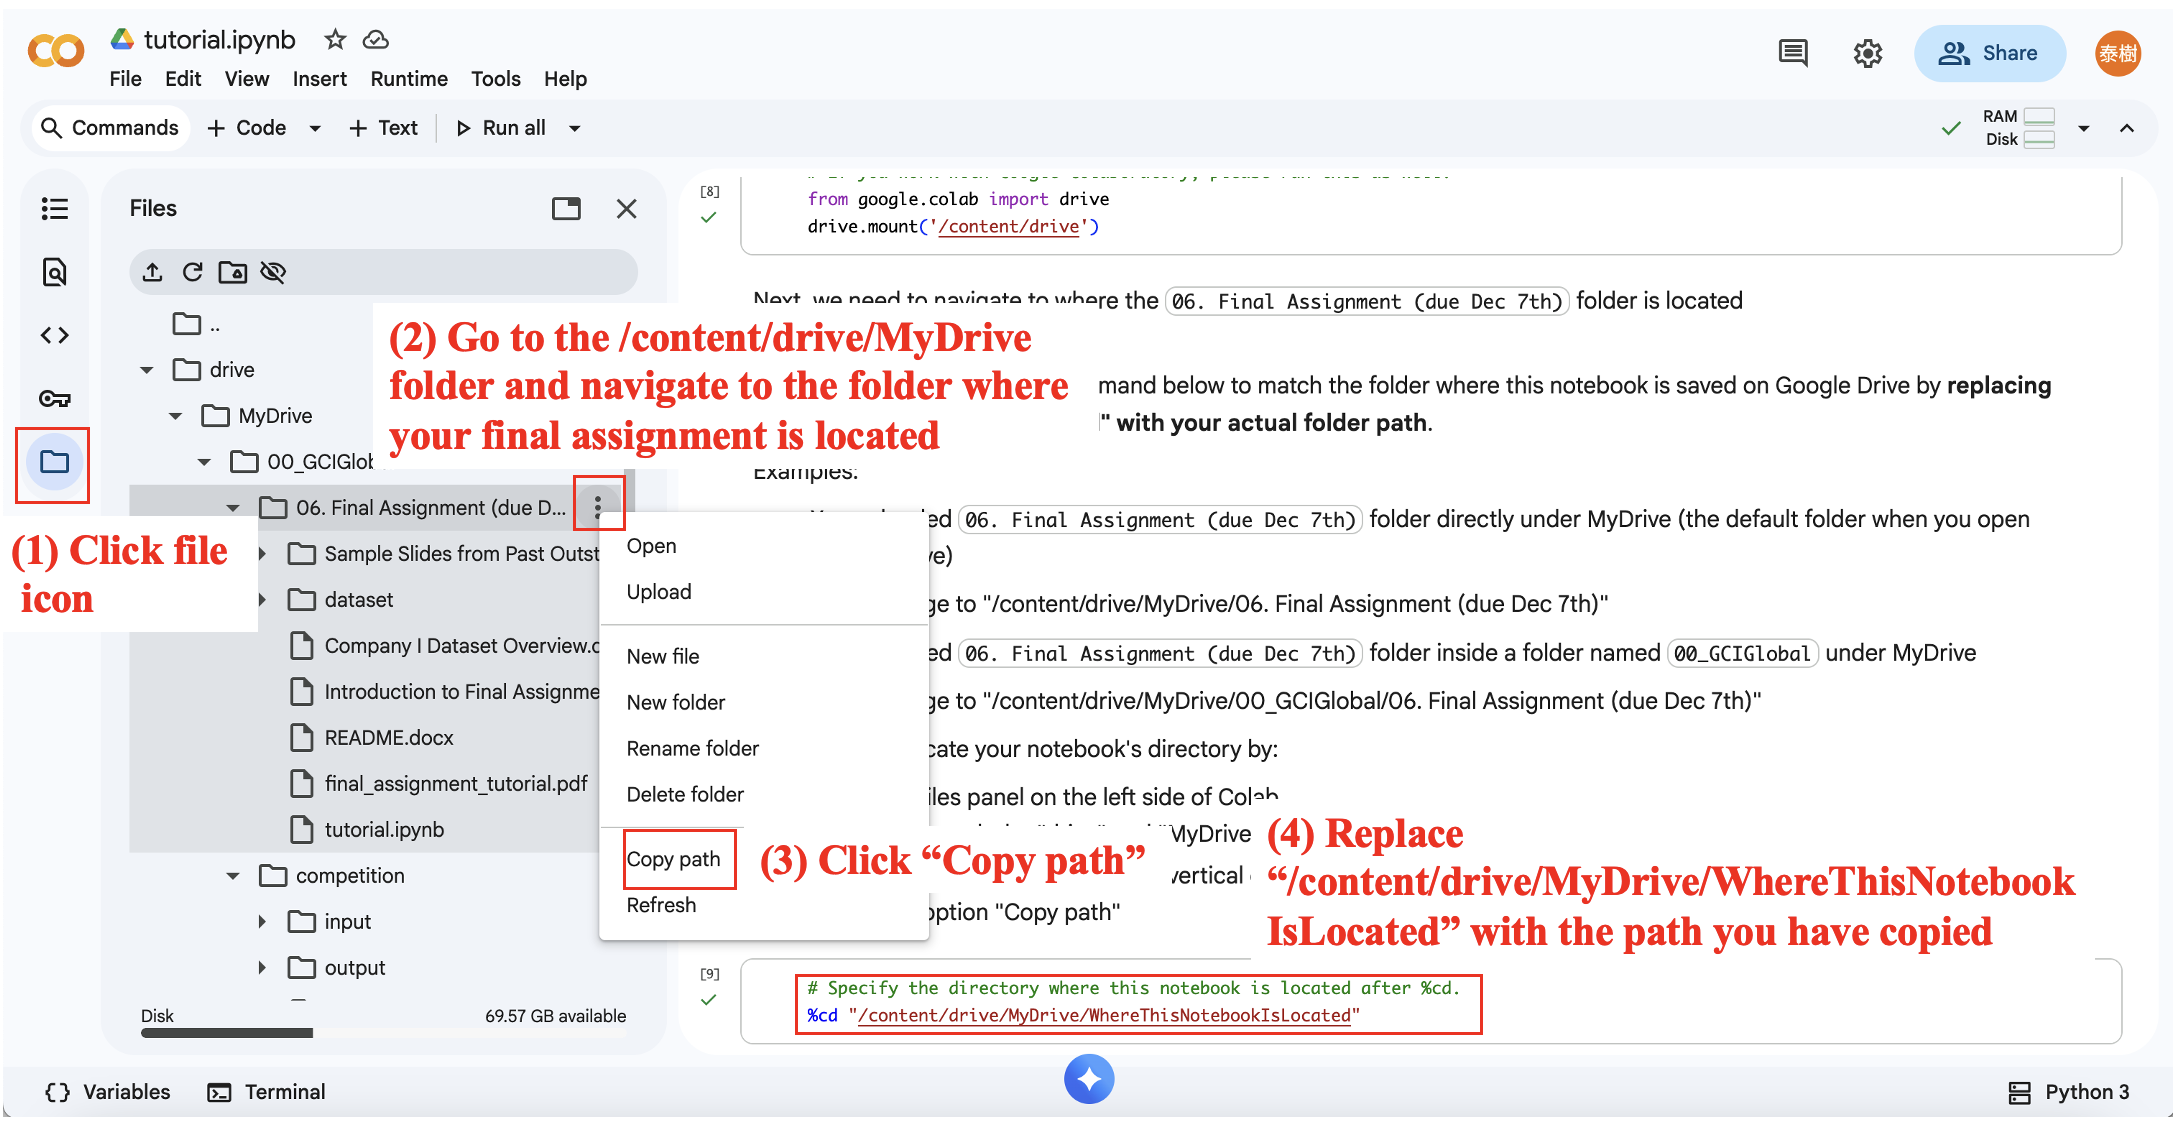

In [ ]:
#%cd "/content/drive/MyDrive/WhereThisNotebookIsLocated"
%cd "/content/drive/MyDrive/Final Assignment"

/content/drive/MyDrive/Final Assignment


###2.3 VERIFYING MY DATASETS PATH IF IT IS CORRECTLY MOUNTED

In [ ]:

from pathlib import Path

# Define the location of our datasets
current_dir = Path.cwd()

client_path = current_dir / "telecom" / "Client.csv"
record_path = current_dir / "telecom" / "Record.csv"

# Verify that both files exist
print("Client.csv found:", client_path.is_file())
print("Record.csv found:", record_path.is_file())


Client.csv found: True
Record.csv found: True


### 2.4 Load the two source tables

The dataset is split across two files:

| File | Granularity | Contents |
|---|---|---|
| `Client.csv` | one row per customer | account-level info: tenure, plan, demographics, equipment |
| `Record.csv` | one row per customer | mean monthly usage, billing, and call-quality metrics, plus the `churn` target |

Both tables share a `Customer_ID` column, which we use to join them into a single analysis table.


In [ ]:
import os
from pathlib import Path

current_dir = Path(os.getcwd())
client_path = current_dir / "telecom" / "Client.csv"
record_path = current_dir / "telecom" / "Record.csv"

for p in (client_path, record_path):
    print(f"{'OK ' if p.exists() else 'MISSING '} {p}")

OK  /content/drive/MyDrive/Final Assignment/telecom/Client.csv
OK  /content/drive/MyDrive/Final Assignment/telecom/Record.csv


In [ ]:
client = pd.read_csv(client_path)
record = pd.read_csv(record_path)

print(f"Client: {client.shape}")
print(f"Record: {record.shape}")

Client: (100000, 50)
Record: (100000, 51)


In [ ]:

# Display the first five rows of each dataset

print("===== CLIENT DATASET =====")
display(client.head())

print("===== RECORD DATASET =====")
display(record.head())


===== CLIENT DATASET =====


,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays,Customer_ID
0,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0,1000001
1,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0,1000002
2,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0,1000003
3,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,1479,40.45,63.23,30.81,8,3,38,50.0,25.0,40.0,T,CHICAGO AREA,N,N,29.98999,1.0,1.0,NaN,0.0,0.0,NaN,6.0,M,M,4.0,M,6.0,1.0,C,D,0.0,U,Y,U,U,U,U,Y,1812.0,1000004
4,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,4452,38.69,249.38,79.50,558,191,55,586.0,196.0,80.0,U,NEW ENGLAND AREA,Y,N,149.98999,6.0,4.0,WCMB,0.0,0.0,R,5.0,M,S,1.0,M,6.0,1.0,C,O,0.0,I,U,U,U,U,U,Y,434.0,1000005


===== RECORD DATASET =====


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.000000,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,1000001
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.000000,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1000002
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.000000,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1000003
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,0.0000,0.000000,0.0,0.000000,0.0,0.000000,0.0,3.666667,0.0,1.333333,0.0,3.666667,0.0,0.000000,0.000000,0.000000,1.333333,0.000000,8.410000,0.0,0.413333,0.333333,0.256667,0.000000,0.000000,1.333333,0.0,3.380000,0.0,3.666667,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60,1000004
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,0.0000,9.666667,0.0,0.666667,0.0,77.000000,0.0,222.333333,0.0,94.666667,0.0,137.000000,0.0,8.666667,15.000000,11.076667,66.000000,0.000000,285.233333,0.0,106.330000,14.666667,10.816667,0.666667,0.366667,97.333333,0.0,173.476667,0.0,90.333333,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57,1000005


In [ ]:

# Examine column names, data types, and non-null counts

print("===== CLIENT DATASET INFO =====")
client.info()

print("\n===== RECORD DATASET INFO =====")
record.info()


===== CLIENT DATASET INFO =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 50 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   uniqsubs          100000 non-null  int64  
 1   actvsubs          100000 non-null  int64  
 2   new_cell          100000 non-null  object 
 3   crclscod          100000 non-null  object 
 4   asl_flag          100000 non-null  object 
 5   totcalls          100000 non-null  int64  
 6   totmou            100000 non-null  float64
 7   totrev            100000 non-null  float64
 8   adjrev            100000 non-null  float64
 9   adjmou            100000 non-null  float64
 10  adjqty            100000 non-null  int64  
 11  avgrev            100000 non-null  float64
 12  avgmou            100000 non-null  float64
 13  avgqty            100000 non-null  float64
 14  avg3mou           100000 non-null  int64  
 15  avg3qty           100000 non-null  in

In [ ]:
# Calculate missing percentages
client_missing = client.isnull().mean() * 100
record_missing = record.isnull().mean() * 100

# Display columns with missing values
print("===== CLIENT MISSING VALUES (%) =====")
print(client_missing[client_missing > 0].sort_values(ascending=False))

print("\n===== RECORD MISSING VALUES (%) =====")
print(record_missing[record_missing > 0].sort_values(ascending=False))

===== CLIENT MISSING VALUES (%) =====
numbcars            49.366
dwllsize            38.308
HHstatin            37.923
ownrent             33.706
dwlltype            31.909
lor                 30.190
income              25.436
adults              23.019
infobase            22.079
hnd_webcap          10.189
prizm_social_one     7.388
avg6mou              2.839
avg6qty              2.839
avg6rev              2.839
truck                1.732
rv                   1.732
ethnic               1.732
kid0_2               1.732
kid3_5               1.732
kid6_10              1.732
kid11_15             1.732
kid16_17             1.732
marital              1.732
forgntvl             1.732
creditcd             1.732
hnd_price            0.847
area                 0.040
refurb_new           0.001
models               0.001
phones               0.001
dualband             0.001
eqpdays              0.001
dtype: float64

===== RECORD MISSING VALUES (%) =====
change_mou     0.891
change_rev     0.891
re

### 2.5 CHECKING DUPLICATES AND MISSING CUSTOMER ID'S

In [ ]:

print("===== CLIENT DATASET =====")
print("Duplicate IDs:", client["Customer_ID"].duplicated().sum())
print("Missing IDs:", client["Customer_ID"].isnull().sum())

print("\n===== RECORD DATASET =====")
print("Duplicate IDs:", record["Customer_ID"].duplicated().sum())
print("Missing IDs:", record["Customer_ID"].isnull().sum())

# Check whether both datasets contain the same customers
client_ids = set(client["Customer_ID"])
record_ids = set(record["Customer_ID"])

print("\n===== MATCHING CHECK =====")
print("IDs only in Client:", len(client_ids - record_ids))
print("IDs only in Record:", len(record_ids - client_ids))


===== CLIENT DATASET =====
Duplicate IDs: 0
Missing IDs: 0

===== RECORD DATASET =====
Duplicate IDs: 0
Missing IDs: 0

===== MATCHING CHECK =====
IDs only in Client: 0
IDs only in Record: 0


In [ ]:
# Merge on Customer_ID. Both tables have one row per customer, so this is a 1:1 join.
df = record.merge(
    client,
    on='Customer_ID',
    how='inner',
    validate="one_to_one"
    )

print(f"Merged: {df.shape}")
df.head()

Merged: (100000, 100)


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.000000,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,1000001,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.000000,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1000002,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.000000,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1000003,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,0.0000,0.000000,0.0,0.000000,0.0,0.000000,0.0,3.666667,0.0,1.333333,0.0,3.666667,0.0,0.000000,0.000000,0.000000,1.333333,0.000000,8.410000,0.0,0.413333,0.333333,0.256667,0.000000,0.000000,1.333333,0.0,3.380000,0.0,3.666667,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60,1000004,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,1479,40.45,63.23,30.81,8,3,38,50.0,25.0,40.0,T,CHICAGO AREA,N,N,29.98999,1.0,1.0,NaN,0.0,0.0,NaN,6.0,M,M,4.0,M,6.0,1.0,C,D,0.0,U,Y,U,U,U,U,Y,1812.0
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,0.0000,9.666667,0.0,0.666667,0.0,77.000000,0.0,222.333333,0.0,94.666667,0.0,137.000000,0.0,8.666667,15.000000,11.076667,66.000000,0.000000,285.233333,0.0,106.330000,14.666667,10.816667,0.666667,0.366667,97.333333,0.0,173.476667,0.0,90.333333,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57,1000005,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,4452,38.69,249.38,79.50,558,191,55,586.0,196.0,80.0,U,NEW ENGLAND AREA,Y,N,149.98999,6.0,4.0,WCMB,0.0,0.0,R,5.0,M,S,1.0,M,6.0,1.0,C,O,0.0,I,U,U,U,U,U,Y,434.0


### 2.6 Final Verification of the Merged Dataset

In [ ]:
print("===== MERGED DATASET VERIFICATION =====")

print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])
print("Duplicate Customer IDs:", df["Customer_ID"].duplicated().sum())
print("Missing Customer IDs:", df["Customer_ID"].isnull().sum())
print("Missing churn labels:", df["churn"].isnull().sum())

# Confirm all original customers were retained
print("All customers retained:", len(df) == len(client) == len(record))

# Check that merging introduced no new missing values
expected_missing = (
    client.isnull().sum().sum()
    + record.isnull().sum().sum()
)

actual_missing = df.isnull().sum().sum()

print("Original missing values:", expected_missing)
print("Merged missing values:", actual_missing)
print("No additional missing values:", expected_missing == actual_missing)

print("\n===== TARGET VALUES =====")
print(df["churn"].value_counts(dropna=False))


===== MERGED DATASET VERIFICATION =====
Total rows: 100000
Total columns: 100
Duplicate Customer IDs: 0
Missing Customer IDs: 0
Missing churn labels: 0
All customers retained: True
Original missing values: 342969
Merged missing values: 342969
No additional missing values: True

===== TARGET VALUES =====
churn
0    50438
1    49562
Name: count, dtype: int64


---

## 3.Exploratory Data Analysis

Before modeling, three questions need answers:

1. **How big and structured is the data?** Rows, columns, dtypes.
2. **Where is the data incomplete or unreliable?**
3. **What does the target variable look like?**

Each answer constrains the next step. The shape and types tell us what preprocessing is required. The missingness tells us which columns may need to be dropped, imputed, or treated specially. The target distribution tells us which metrics will be meaningful.

EDA is also where the proposal starts to take shape — the patterns you see now become candidate signals for the model and anchors for the story your proposal will tell. The visualizations in this tutorial are intentionally minimal — just enough to make a point; for your proposal slides, you will want to polish them.

### 3.1 CUSTOMER CHURN DISTRIBUTION VISUALIZATION

===== CHURN DISTRIBUTION =====
churn
0    50438
1    49562
Name: count, dtype: int64

===== CHURN PERCENTAGES =====
churn
0    50.44
1    49.56
Name: proportion, dtype: float64


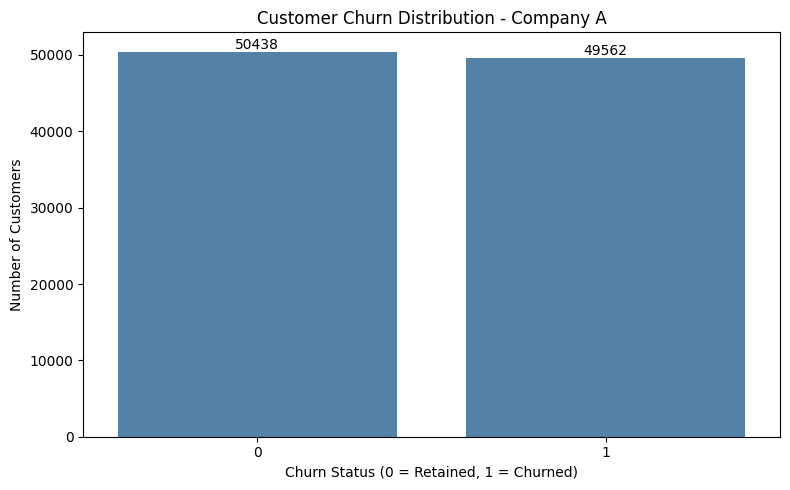

In [ ]:
# Calculate churn counts and percentages
churn_counts = df["churn"].value_counts().sort_index()
churn_percentages = df["churn"].value_counts(
    normalize=True
).sort_index() * 100

print("===== CHURN DISTRIBUTION =====")
print(churn_counts)

print("\n===== CHURN PERCENTAGES =====")
print(churn_percentages.round(2))

# Visualize churn distribution
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="churn",
    color="steelblue"
)

plt.title("Customer Churn Distribution - Company A")
plt.xlabel("Churn Status (0 = Retained, 1 = Churned)")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()


Key findings
1. The dataset is nearly balanced. There are approximately equal numbers of churned and retained customers.
2. There is no major class imbalance. We do not currently need to apply balancing techniques such as SMOTE solely because of the target distribution.
3. The business problem is worth investigating. The dataset contains substantial numbers of churn cases, but we cannot assume the sample's 49.56% churn proportion represents the company's actual customer churn rate.

### 3.2 Analyzing Numerical Features by Churn Status:
This ivestigates how customer churn and retain differs



In [ ]:
# Select business-relevant numerical features
features = [
    "rev_Mean",
    "mou_Mean",
    "change_mou",
    "custcare_Mean",
    "eqpdays",
    "months"
]

# Calculate median values for each churn group
comparison = df.groupby("churn")[features].median()

print("===== NUMERICAL FEATURES BY CHURN =====")
print("0 = Retained, 1 = Churned")

display(comparison.T.round(2))


===== NUMERICAL FEATURES BY CHURN =====
0 = Retained, 1 = Churned


churn,0,1
rev_Mean,48.88,47.49
mou_Mean,380.50,329.75
change_mou,-3.00,-10.00
custcare_Mean,0.00,0.00
eqpdays,310.00,366.00
months,16.00,17.00


What are the most interesting discoveries?

**Finding 1** — Churned customers use fewer minutes
Churned customers have a median monthly usage of 329.75 minutes compared with 380.50 minutes among retained customers. This suggests that declining or lower engagement may be associated with churn.

**Finding 2** — Churned customers have older handsets, Their median handset age is 366 days, compared with 310 days for retained customers. This gives us a hypothesis worth testing: handset age may help identify customers at risk of leaving.

**Finding 3 — **Churned customers show larger usage declines, change_mou is −10 for churned customers versus −3 for retained customers.
The documentation's units need clarification, so we will report these as dataset values for now rather than percentages.

The median customer care calls are zero in both groups. This does not mean customer service has no relationship with churn; we will need to examine the wider distribution.

Also, these are associations, not evidence of causation.

### 3.3 Visualization of Usage and Handset Age

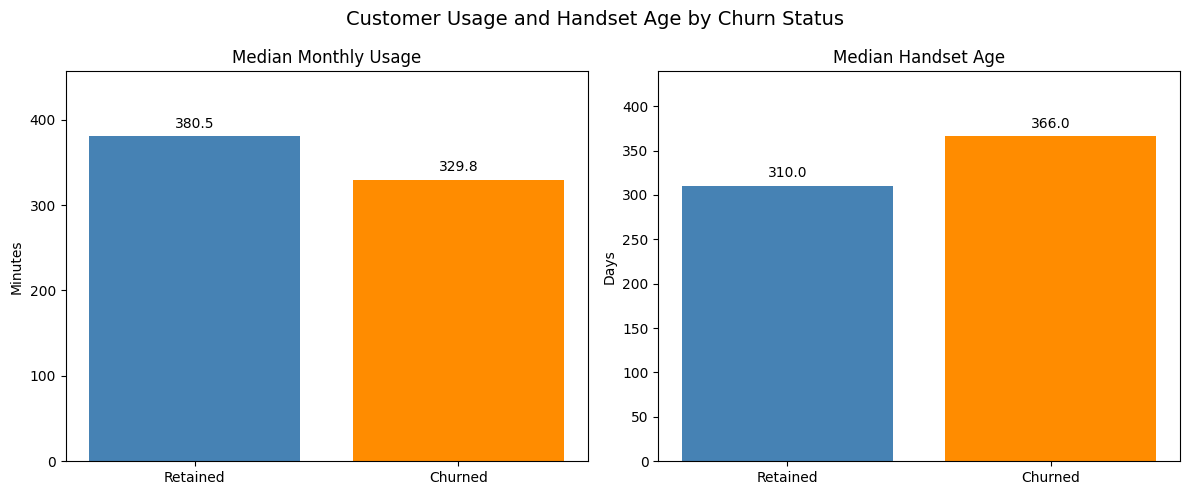

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

features_to_plot = [
    ("mou_Mean", "Median Monthly Usage", "Minutes"),
    ("eqpdays", "Median Handset Age", "Days")
]

colors = ["steelblue", "darkorange"]

for ax, (feature, title, ylabel) in zip(axes, features_to_plot):

    values = comparison[feature]

    bars = ax.bar(
        ["Retained", "Churned"],
        values,
        color=colors
    )

    ax.bar_label(bars, fmt="%.1f", padding=4)

    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, values.max() * 1.2)

plt.suptitle(
    "Customer Usage and Handset Age by Churn Status",
    fontsize=14
)

plt.tight_layout()
plt.show()


The preliminary business hypothesis: Lower customer engagement and older handsets may be useful indicators of customer churn.

However, comparing medians does not tell us how much churn risk increases across different customer segments.

### 3.4 Investigate Churn Rate by Handset Age

===== CHURN RATE BY HANDSET AGE =====


,age_group,customers,churn_rate
0,0-180 days,18194,41.78
1,181-365 days,36356,46.97
2,366-730 days,34505,53.84
3,Over 730 days,10811,57.89


Excluded missing/negative handset ages: 134


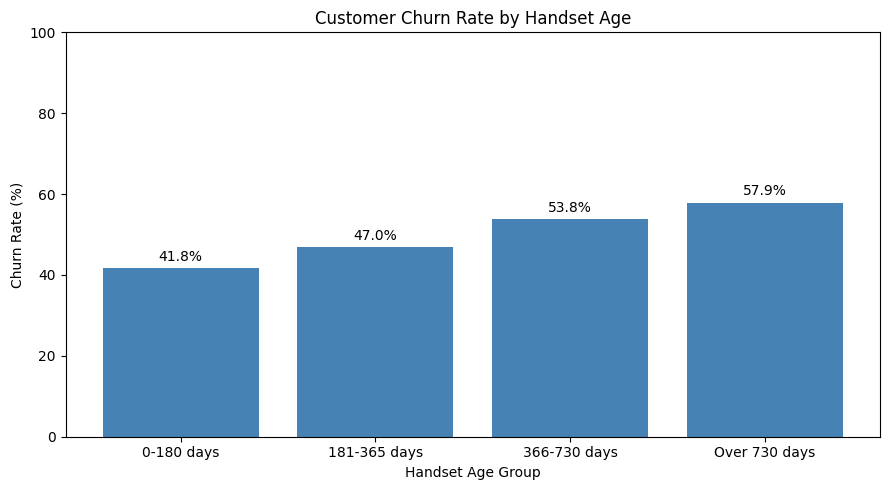

In [ ]:
# Keep valid handset ages for this analysis
age_df = df[
    df["eqpdays"].notna() &
    (df["eqpdays"] >= 0)
].copy()

# Create handset age groups
bins = [-0.001, 180, 365, 730, float("inf")]

labels = [
    "0-180 days",
    "181-365 days",
    "366-730 days",
    "Over 730 days"
]

age_df["age_group"] = pd.cut(
    age_df["eqpdays"],
    bins=bins,
    labels=labels
)

# Calculate churn rate and customer count
age_summary = age_df.groupby(
    "age_group", observed=True
)["churn"].agg(
    customers="count",
    churn_rate="mean"
).reset_index()

age_summary["churn_rate"] *= 100

print("===== CHURN RATE BY HANDSET AGE =====")
display(age_summary.round(2))

print("Excluded missing/negative handset ages:",
      len(df) - len(age_df))

# Visualize
plt.figure(figsize=(9, 5))

bars = plt.bar(
    age_summary["age_group"],
    age_summary["churn_rate"],
    color="steelblue"
)

plt.bar_label(bars, fmt="%.1f%%", padding=3)

plt.title("Customer Churn Rate by Handset Age")
plt.xlabel("Handset Age Group")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()


What does this mean for Company A?
Customers with older handsets have higher observed churn rates in this dataset.

This suggests a potential business opportunity: Company A could investigate targeted handset-upgrade or customer-retention programs for customers with aging devices.

However, we must consider two limitations:
- The relationship does not prove that older handsets cause customers to leave.
- We need the number of customers in each handset-age group to assess how reliable and commercially important the differences are.

This analysis excluded 134 customers with missing or negative handset ages.

### 3.5  Usage Changes and Custom
We want to determine whether customers with larger usage declines also have higher churn rates.

===== HANDSET AGE GROUP SUMMARY =====


,age_group,customers,churn_rate
0,0-180 days,18194,41.78
1,181-365 days,36356,46.97
2,366-730 days,34505,53.84
3,Over 730 days,10811,57.89



===== CHURN RATE BY USAGE CHANGE =====


,usage_group,customers,churn_rate
0,"(-3875.001, -87.0]",24805,53.37
1,"(-87.0, -6.25]",24863,49.35
2,"(-6.25, 63.0]",24702,48.09
3,"(63.0, 31219.25]",24739,46.48


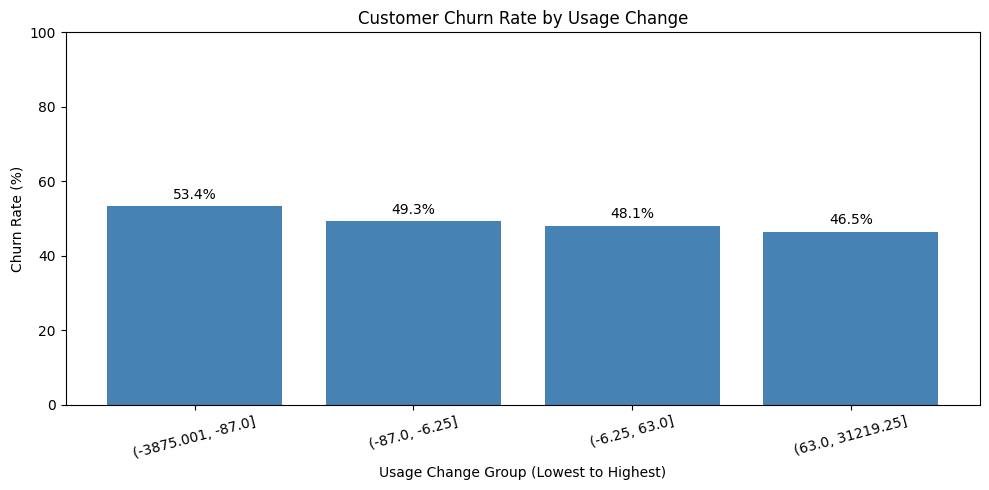

In [ ]:

# Step 2.5: Churn Rate by Usage Change

# First display handset-age group sample sizes
print("===== HANDSET AGE GROUP SUMMARY =====")
display(age_summary.round(2))

# Exclude missing usage-change values
usage_df = df.dropna(subset=["change_mou"]).copy()

# Divide customers into four usage-change groups
usage_df["usage_group"] = pd.qcut(
    usage_df["change_mou"],
    q=4,
    duplicates="drop"
)

# Calculate churn rate for each group
usage_summary = usage_df.groupby(
    "usage_group", observed=True
)["churn"].agg(
    customers="count",
    churn_rate="mean"
).reset_index()

usage_summary["churn_rate"] *= 100

print("\n===== CHURN RATE BY USAGE CHANGE =====")
display(usage_summary.round(2))

# Create visualization
plt.figure(figsize=(10, 5))

bars = plt.bar(
    range(len(usage_summary)),
    usage_summary["churn_rate"],
    color="steelblue"
)

plt.xticks(
    range(len(usage_summary)),
    [str(x) for x in usage_summary["usage_group"]],
    rotation=15
)

plt.bar_label(bars, fmt="%.1f%%", padding=3)

plt.title("Customer Churn Rate by Usage Change")
plt.xlabel("Usage Change Group (Lowest to Highest)")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()


**Key observation:** The oldest handset group has a churn rate 16.11 percentage points higher than the youngest group.

This supports investigating handset age as a potential churn predictor.

Customers experiencing the greatest usage declines have higher observed churn rates.

I have excluded 891 customers whose change_mou values were missing. The relationship appears consistent across the four groups, although the feature contains extreme values and its exact units remain uncertain.

The emerging hypothesis: Customers with aging handsets and declining usage may represent a particularly vulnerable customer segment.

This is still a hypothesis, not a final conclusion.

### 3.6 Investigate Combined Churn Risk
The examined handset age and usage change separately. Now i will examine them together,
This is important because a combination of warning signs may help Company A identify priority customers for retention programs.

What are we expecting?
compare four customer segments:
- Newer handset + declining usage
- Newer handset + stable/increasing usage
- Older handset + declining usage
- Older handset + stable/increasing usage

For this analysis, an older handset means more than 365 days, and declining usage means change_mou is negative. These are exploratory thresholds, not established optimal targeting rules.

Also will examine which segment has the highest churn rate, how many customers it contains, and whether the combined analysis adds insight beyond the individual features.

===== COMBINED CHURN RISK =====


,handset_group,usage_trend,customers,churn_rate
0,Newer handset,Declining usage,28824,47.14
1,Newer handset,Stable/increasing usage,25427,42.75
2,Older handset,Declining usage,24768,55.97
3,Older handset,Stable/increasing usage,19956,52.70


Customers included: 98975


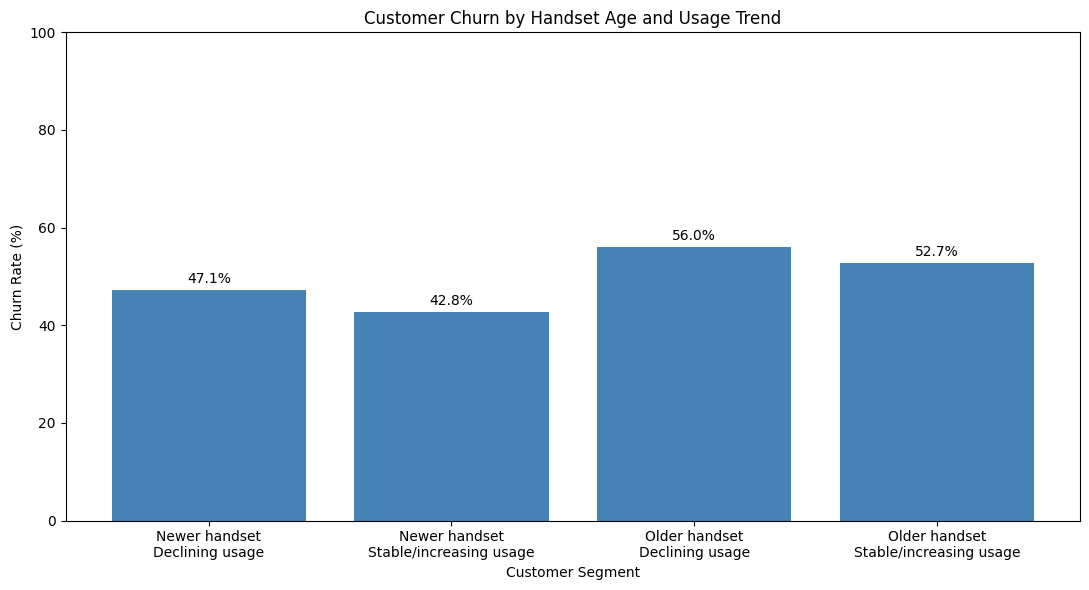

In [ ]:

# Step 2.6: Combined Handset Age and Usage Analysis

# Select customers with valid information
risk_df = df[
    df["eqpdays"].notna() &
    (df["eqpdays"] >= 0) &
    df["change_mou"].notna()
].copy()

# Classify customers by handset age
risk_df["handset_group"] = np.where(
    risk_df["eqpdays"] > 365,
    "Older handset",
    "Newer handset"
)

# Classify customers by usage change
risk_df["usage_trend"] = np.where(
    risk_df["change_mou"] < 0,
    "Declining usage",
    "Stable/increasing usage"
)

# Calculate churn statistics
risk_summary = risk_df.groupby(
    ["handset_group", "usage_trend"]
)["churn"].agg(
    customers="count",
    churn_rate="mean"
).reset_index()

risk_summary["churn_rate"] *= 100

print("===== COMBINED CHURN RISK =====")
display(risk_summary.round(2))

print("Customers included:", len(risk_df))

# Visualize
risk_summary["segment"] = (
    risk_summary["handset_group"] +
    "\n" +
    risk_summary["usage_trend"]
)

plt.figure(figsize=(11, 6))

bars = plt.bar(
    risk_summary["segment"],
    risk_summary["churn_rate"],
    color="steelblue"
)

plt.bar_label(bars, fmt="%.1f%%", padding=3)

plt.title("Customer Churn by Handset Age and Usage Trend")
plt.ylabel("Churn Rate (%)")
plt.xlabel("Customer Segment")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()


**What have we discovered?**
The segment with both an older handset and declining usage has the highest observed churn rate.

Notably, this segment contains 24,768 customers, approximately 25% of the 98,975 customers included in this analysis.

**Now we have a potential business opportunity:**

Company A could investigate using handset age and changes in usage to prioritize customers for proactive retention interventions.

However, we still need to confirm whether these variables remain useful when other factors are considered. We also cannot conclude that handset upgrades or interventions would reduce churn without testing them.

### 3.7 Analyzing Customer Care and Churn

Previously, the median was zero for both churned and retained customers. But a median of zero does not mean customer care activity is irrelevant.

**Our research question is:**

Do customers who contact customer care more frequently have higher churn rates?

**Why is this important?**

 It could indicate service-related problems worth investigating.

===== CUSTOMER CARE AND CHURN =====


,care_group,customers,churn_rate
0,No calls,55692,51.76
1,More than 0 to 1,16100,49.40
2,More than 1 to 3,12186,46.18
3,More than 3,16022,44.66


Customers included: 100000


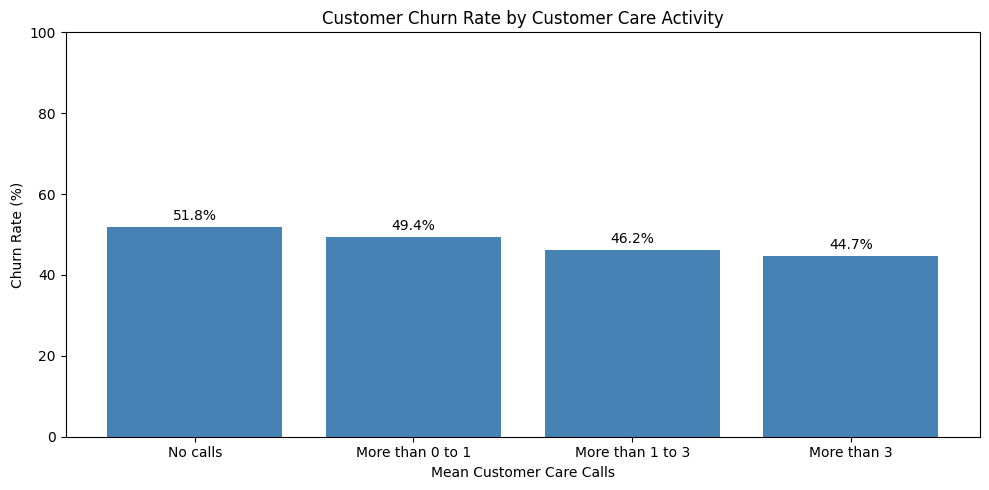

In [ ]:

# Step 2.7: Customer Care Calls and Churn

# Create customer care activity groups
care_df = df.copy()

care_df["care_group"] = pd.cut(
    care_df["custcare_Mean"],
    bins=[-0.001, 0, 1, 3, float("inf")],
    labels=[
        "No calls",
        "More than 0 to 1",
        "More than 1 to 3",
        "More than 3"
    ]
)

# Calculate customer counts and churn rates
care_summary = care_df.groupby(
    "care_group", observed=True
)["churn"].agg(
    customers="count",
    churn_rate="mean"
).reset_index()

care_summary["churn_rate"] *= 100

print("===== CUSTOMER CARE AND CHURN =====")
display(care_summary.round(2))

# Check grouping coverage
print("Customers included:",
      care_summary["customers"].sum())

# Create visualization
plt.figure(figsize=(10, 5))

bars = plt.bar(
    care_summary["care_group"],
    care_summary["churn_rate"],
    color="steelblue"
)

plt.bar_label(bars, fmt="%.1f%%", padding=3)

plt.title("Customer Churn Rate by Customer Care Activity")
plt.xlabel("Mean Customer Care Calls")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()


**What have we discovered?**

Customers with more customer care activity have lower observed churn rates in this dataset. This is the opposite of what we might initially expect if customer service calls mainly represented complaints.

**There are several possible explanations:**
- Customers contacting support may be more engaged with the provider.
- Some service interactions may help customers resolve problems.
- Customers intending to leave may disengage without contacting customer care.
- Other customer characteristics may explain some or all of the association.
These explanations are hypotheses. Our data does not establish that customer care calls prevent churn.

**Business implication:** We should investigate customer engagement and support accessibility rather than immediately assuming that frequent service calls indicate dissatisfaction.

### 3.8 Analyzing Network Service Quality and Churn

Here the question is Do customers experiencing a higher proportion of failed calls have higher churn rates?

We will calculate a call failure ratio so that customers with different numbers of attempted calls can be compared more fairly.

This analysis will excludes customers with zero attempts or invalid ratios. We will examine the exclusion count before drawing business conclusions.

===== NETWORK FAILURE AND CHURN =====


,failure_group,customers,churn_rate
0,0-1%,4985,49.69
1,>1-5%,36131,46.92
2,>5-10%,32097,48.77
3,>10%,18623,52.53


Customers included: 91836
Customers excluded: 8164


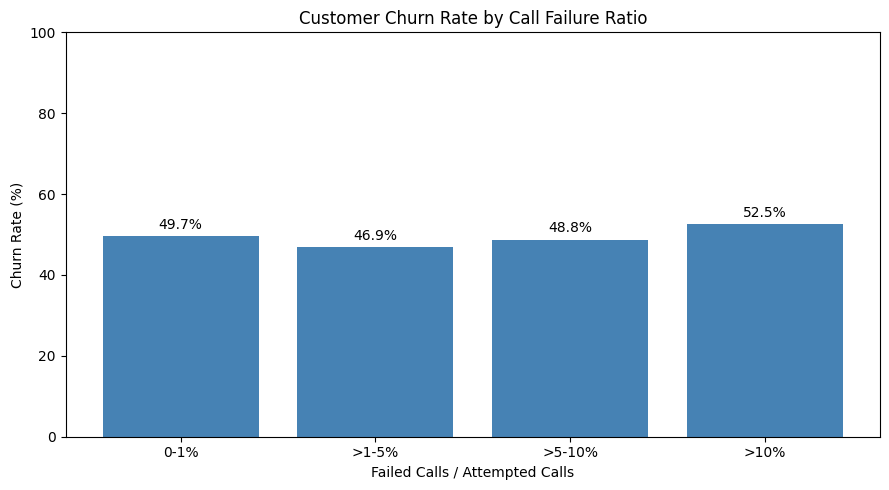

In [ ]:

# Step 2.8: Network Quality and Customer Churn

network_df = df.copy()

# Calculate the proportion of attempted calls that failed
network_df["failure_rate"] = np.where(
    network_df["attempt_Mean"] > 0,
    network_df["drop_blk_Mean"] /
    network_df["attempt_Mean"],
    np.nan
)

# Keep valid ratios between 0 and 1
network_df = network_df[
    network_df["failure_rate"].between(0, 1)
].copy()

# Create failure-rate groups
network_df["failure_group"] = pd.cut(
    network_df["failure_rate"],
    bins=[-0.001, 0.01, 0.05, 0.10, 1.0],
    labels=[
        "0-1%",
        ">1-5%",
        ">5-10%",
        ">10%"
    ]
)

# Calculate churn rate by group
network_summary = network_df.groupby(
    "failure_group", observed=True
)["churn"].agg(
    customers="count",
    churn_rate="mean"
).reset_index()

network_summary["churn_rate"] *= 100

print("===== NETWORK FAILURE AND CHURN =====")
display(network_summary.round(2))

print("Customers included:", len(network_df))
print("Customers excluded:", len(df) - len(network_df))

# Plot results
plt.figure(figsize=(9, 5))

bars = plt.bar(
    network_summary["failure_group"],
    network_summary["churn_rate"],
    color="steelblue"
)

plt.bar_label(bars, fmt="%.1f%%", padding=3)

plt.title("Customer Churn Rate by Call Failure Ratio")
plt.xlabel("Failed Calls / Attempted Calls")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()


**Our findings**

**Finding 1** — High failure ratios are associated with higher churn. Customers with failure ratios exceeding 10% show the highest observed churn rate at 52.53%.

**Finding 2** — The relationship is not perfectly linear. The 0–1% group has higher churn than the >1–5% group. Therefore, we cannot conclude that churn increases continuously with every increase in the call failure ratio.

**Finding 3**— Some customers were excluded.
The cistomer analyzed are 91,836 which is approximately 91.84% of datasets but we have the 8.16% of datasets excluded which approximately equal to 8,164 customers.

The exclusions include customers for whom the ratio was undefined or outside the valid range. We must document this limitation because excluded customers may differ from those retained.

**Business interpretation**:

Network reliability is another promising area to investigate alongside handset age and usage behavior.

However, the analysis does not prove that network failures cause churn. Other customer characteristics could influence the observed relationship.

### 3.9 Analyzing Customer Revenue and Churn

So far, we have examined customer behavior, handset age, support activity, and network quality.

But we must also answer an important question: ***Which customer revenue segments are experiencing greater churn?***

This matters because losing a higher-revenue customer may have a different financial impact from losing a lower-revenue customer.

===== REVENUE AND CHURN =====


,revenue_group,customers,median_revenue,churn_rate
0,"(-6.1690000000000005, 33.26]",24921,29.76,52.65
1,"(33.26, 48.195]",24901,38.66,47.70
2,"(48.195, 70.75]",24911,56.04,49.01
3,"(70.75, 3843.262]",24910,95.27,48.61


Customers included: 99643
Customers excluded: 357


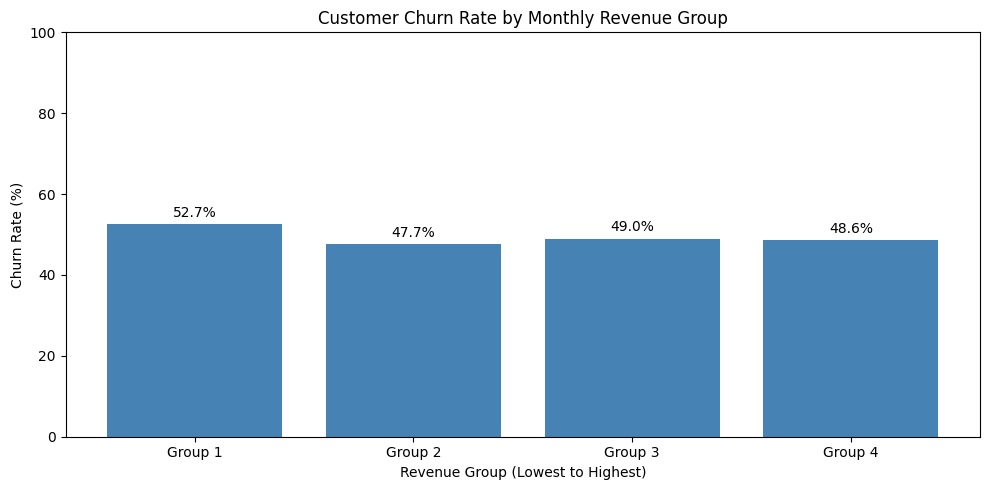

In [ ]:

# Step 2.9: Customer Revenue and Churn

# Keep customers with recorded monthly revenue
revenue_df = df.dropna(subset=["rev_Mean"]).copy()

# Divide customers into four revenue groups
revenue_df["revenue_group"] = pd.qcut(
    revenue_df["rev_Mean"],
    q=4,
    duplicates="drop"
)

# Calculate churn rate and median revenue
revenue_summary = revenue_df.groupby(
    "revenue_group", observed=True
).agg(
    customers=("churn", "count"),
    median_revenue=("rev_Mean", "median"),
    churn_rate=("churn", "mean")
).reset_index()

revenue_summary["churn_rate"] *= 100

print("===== REVENUE AND CHURN =====")
display(revenue_summary.round(2))

print("Customers included:", len(revenue_df))
print("Customers excluded:", len(df) - len(revenue_df))

# Visualize churn rates
plt.figure(figsize=(10, 5))

labels = [
    f"Group {i+1}"
    for i in range(len(revenue_summary))
]

bars = plt.bar(
    labels,
    revenue_summary["churn_rate"],
    color="steelblue"
)

plt.bar_label(bars, fmt="%.1f%%", padding=3)

plt.title("Customer Churn Rate by Monthly Revenue Group")
plt.xlabel("Revenue Group (Lowest to Highest)")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()


**What have we discovered?**

**Finding 1**— Lower-revenue customers show the highest churn rate. Group 1 has a 52.65% churn rate, compared with 48.61% for Group 4, a difference of 4.04 percentage points.

**Finding 2** — Churn does not consistently decrease as revenue increases. Group 3 has slightly higher churn than Groups 2 and 4. Therefore, the relationship is not strictly linear.

**Finding 3** — High-revenue customers still face considerable churn risk. Although Group 4 does not have the highest churn rate, losing these customers may create substantial financial exposure.

**This raises an important business question:**

Should Company A prioritize customers with the highest churn probability, or customers whose departure would have the greatest financial consequences?

**Important data-quality observation:**

The revenue analysis included 99,643 customers and excluded 357 with missing monthly revenue.

The observed revenue range also includes negative values and extremely high values.

We must investigate these before performing financial calculations. The currency is not specified in the documentation.

### 3.1.0 Identifying High-Risk, High-Revenue Customers

We want to identify customers who have both:
- Warning signs associated with higher churn: older handsets and declining usage.
- Higher recorded monthly revenue, making their potential loss commercially important.

This will help us distinguish between customers who are more likely to churn and those who may have greater financial value.

In [ ]:

# Step 2.10: High-Risk and High-Revenue Segmentation

# Keep records with valid values for this analysis
business_df = df[
    df["eqpdays"].notna() &
    (df["eqpdays"] >= 0) &
    df["change_mou"].notna() &
    df["rev_Mean"].notna() &
    (df["rev_Mean"] >= 0)
].copy()

# Define an exploratory higher-risk segment
business_df["risk_group"] = np.where(
    (business_df["eqpdays"] > 365) &
    (business_df["change_mou"] < 0),
    "Older handset + declining usage",
    "Other customers"
)

# Define high revenue as the top 25% of valid revenue
revenue_threshold = business_df["rev_Mean"].quantile(0.75)

business_df["revenue_level"] = np.where(
    business_df["rev_Mean"] >= revenue_threshold,
    "High revenue",
    "Other revenue"
)

# Calculate business segment statistics
business_summary = business_df.groupby(
    ["risk_group", "revenue_level"]
).agg(
    customers=("churn", "count"),
    churn_rate=("churn", "mean"),
    median_revenue=("rev_Mean", "median")
).reset_index()

business_summary["churn_rate"] *= 100

print("===== BUSINESS SEGMENT ANALYSIS =====")
print("High-revenue threshold:", round(revenue_threshold, 2))
print("Customers included:", len(business_df))
print("Customers excluded:", len(df) - len(business_df))

display(business_summary.round(2))


===== BUSINESS SEGMENT ANALYSIS =====
High-revenue threshold: 70.76
Customers included: 98973
Customers excluded: 1027


,risk_group,revenue_level,customers,churn_rate,median_revenue
0,Older handset + declining usage,High revenue,4223,55.67,90.65
1,Older handset + declining usage,Other revenue,20545,56.03,35.69
2,Other customers,High revenue,20522,46.99,96.35
3,Other customers,Other revenue,53683,47.19,39.82


**What does this mean?**

This is a promising segment for Company A to investigate.

These customers have relatively high recorded monthly revenue and behavioral characteristics associated with greater churn.

Interestingly, within the older-handset and declining-usage segment, the churn rates are almost identical across revenue levels: 55.67% and 56.03%.

This suggests that customer revenue and churn risk should be considered separately when deciding whom to prioritize.

We should not yet claim that targeting these customers will generate revenue savings. That requires a validated predictive model, realistic cost assumptions, and evidence that retention interventions work.

### 3.1.1 Visualize Our Business Opportunity

We will now produce one graph comparing the two higher-revenue customer groups. This will help communicate our finding to nontechnical executives.

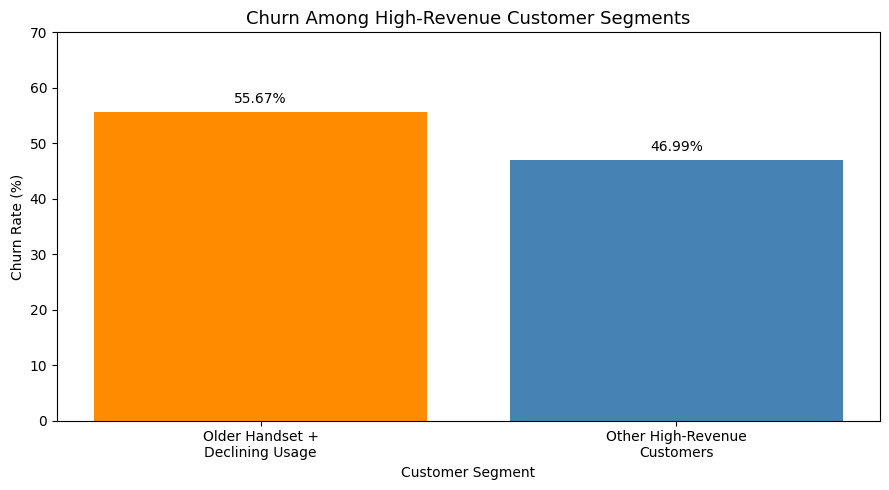

===== HIGH-REVENUE SEGMENT COMPARISON =====


,risk_group,customers,churn_rate,median_revenue
0,Older handset + declining usage,4223,55.67,90.65
2,Other customers,20522,46.99,96.35


In [ ]:
# Select high-revenue customers
high_revenue = business_summary[
    business_summary["revenue_level"] == "High revenue"
].copy()

# Create readable labels
high_revenue["segment"] = high_revenue["risk_group"].map({
    "Older handset + declining usage":
        "Older Handset +\nDeclining Usage",
    "Other customers":
        "Other High-Revenue\nCustomers"
})

# Visualize
plt.figure(figsize=(9, 5))

bars = plt.bar(
    high_revenue["segment"],
    high_revenue["churn_rate"],
    color=["darkorange", "steelblue"]
)

plt.bar_label(bars, fmt="%.2f%%", padding=4)

plt.title(
    "Churn Among High-Revenue Customer Segments",
    fontsize=13
)

plt.xlabel("Customer Segment")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 70)

plt.tight_layout()
plt.show()

# Display supporting figures
print("===== HIGH-REVENUE SEGMENT COMPARISON =====")

display(
    high_revenue[
        ["risk_group", "customers",
         "churn_rate", "median_revenue"]
    ].round(2)
)


**Business interpretation:**

We have identified a segment that Company A could prioritize for further investigation: higher-revenue customers with older handsets and declining usage.

But this is an exploratory risk segment, not a machine-learning prediction. We have not demonstrated that a retention offer will prevent churn or generated a validated estimate of financial savings.

For our final business proposal, the machine-learning model will help determine whether we can rank customers more effectively than these simple rules.

### **3.1.2 Document Our Final EDA Findings**


### 3.1.3 EDA Summary and Business Insights

### Key Findings

1. The dataset contains 100,000 customers, with an observed churn rate of 49.56%.
2. Customers who churned had lower median monthly usage (329.75 vs. 380.50 minutes).
3. Customers with older handsets showed higher observed churn rates.
4. Customers experiencing greater usage declines showed higher churn rates.
5. Customers with no recorded customer care calls had higher churn than those with frequent calls.
6. Customers with call failure ratios above 10% had an observed churn rate of 52.53%.
7. The lowest monthly revenue quartile had the highest observed churn rate (52.65%).
8. A segment of 4,223 higher-revenue customers with older handsets and declining usage showed 55.67% churn.

### Preliminary Business Hypothesis

Company A could investigate a targeted customer-retention strategy using customer engagement, handset age, and financial value.

### Limitations

- Observed associations do not establish causation.
- The sample churn rate may not represent the company's operational churn rate.
- Some variables contain missing, negative, or extreme values.
- Revenue currency and intervention effectiveness are not established.
- Machine-learning evaluation is needed before selecting a targeting strategy.

### Source

Company A, Client.csv and Record.csv;

GCI World 2026 Final Assignment.

Analysis conducted by the author.


# **4. Define Company A's Core Business Problem**

### 4.1 Business Problem Definition

**Proposed Project Title:**

Predictive Customer Retention: A Machine Learning-Based Strategy for Reducing Telecommunications Customer Churn.

**Business Problem:**

Company A faces the challenge of identifying customers who may discontinue their telecommunications services. Without reliable risk identification, retention resources may be directed toward customers who are unlikely to leave, while potentially valuable at-risk customers receive insufficient attention.

**Evidence from EDA:**

- Customers with older handsets and declining usage demonstrated a 55.97% observed churn rate.
- A segment of 4,223 higher-revenue customers with these characteristics experienced 55.67% observed churn.
- Customers with call-failure ratios exceeding 10% demonstrated a 52.53% observed churn rate.
- These findings identify potential warning indicators but do not establish the causes of churn.

**Business Objective:**

Develop a data-driven customer-retention strategy that identifies customers with elevated churn risk and helps Company A prioritize commercially appropriate retention interventions.

**Machine Learning Objective:**

Build and evaluate a binary classification model that predicts whether a customer will churn during the documented 31–60-day period following observation.

Target variable: `churn`

- `0` = Customer retained.
- `1` = Customer churned.

**Proposed Business Solution:**

Use predicted churn probabilities, customer value indicators, and intervention costs to prioritize targeted retention activities, such as customer engagement, service assistance, and appropriate handset or plan reviews.

**Proposed Success Measures:**

1. Predictive performance: ROC-AUC and lift among highest-risk customers.
2. Operational performance: Ability to identify actionable customer segments.
3. Business performance: Incremental churn reduction and net financial benefit, to be evaluated through a controlled pilot.

**Important Limitation:**

The dataset supports predicting churn risk, but it does not establish whether particular interventions will prevent customers from leaving. Actual financial impact will depend on additional assumptions and pilot validation.

**Source:** Company A dataset; author's exploratory analysis. Supporting industry context: References R1–R5.

## 4.2 Researching the Telecommunications Market

## 4.3 Market Research and Business Problem Definition

### Telecommunications Industry Market Research

**[R1] GSMA Intelligence (2025) — Customer Churn and Retention**

GSMA Intelligence reported that approximately one in seven mobile users switched service providers within the previous 12 months, averaged across 12 major markets studied. Value for money was the leading reason for switching. Network quality and service bundling were also identified as potential areas for improving customer retention.

**Relevance to Company A:** Customer churn is an established challenge in telecommunications. Our exploratory analysis investigates whether usage behavior, handset age, and service quality can help identify customers at risk of leaving.

Source: GSMA Intelligence. (2025). *The mobile churn challenge: Where loyalty is lowest and four recommendations for operators.*

https://www.gsmaintelligence.com/research/the-mobile-churn-challenge-where-loyalty-is-lowest-and-four-recommendations-for-operators

---

**[R2] J.D. Power (2025) — Network Quality and Customer Switching**

The 2025 U.S. Wireless Network Quality Performance Study identified network quality as the second most important reason for customers switching carriers, after price.

**Relevance to Company A:** Our EDA found that customers with call-failure ratios exceeding 10% had an observed churn rate of 52.53%. This supports further investigation of network reliability as a possible churn indicator.

Source: J.D. Power. (2025, January 16). *2025 U.S. Wireless Network Quality Performance Study — Volume 1.*

https://www.jdpower.com/business/press-releases/2025-us-wireless-network-quality-performance-study-volume-1

---

**[R3] GSMA (2026) — The Mobile Economy Africa**

According to GSMA, mobile technologies and services contributed approximately US$240 billion to Africa's economy in 2025, representing 7.8% of regional GDP.

The report highlights device affordability, digital skills, and mobile internet adoption as major challenges. It also identifies growing adoption of artificial intelligence for network optimization and customer service.

**Relevance to Company A:** These findings provide African industry context for investigating handset-related challenges and machine-learning applications in telecommunications. They do not establish the reasons for churn among Company A's customers.

Source: GSMA. (2026). *The Mobile Economy Africa 2026.*

https://www.gsma.com/solutions-and-impact/connectivity-for-good/mobile-economy/africa/

---

**[R4] Communications Authority of Kenya (2024) — Quality of Service**

Kenya's Communications Authority reported that Airtel Kenya and Telkom Kenya failed to meet the required 80% Quality of Service performance threshold in the assessment for the year ending June 2023.

The regulator identified problems involving unsuccessful calls, network coverage, and internet service indicators.

**Relevance to Company A:** This provides an African regulatory example demonstrating the importance of network performance. Our EDA also found elevated churn among customers with high call-failure ratios.

Source: Communications Authority of Kenya. (2024, January 18). *CA warns Airtel and Telkom Kenya on poor quality services.*

https://www.ca.go.ke/node/644

---

**[R5] Tanzania Communications Regulatory Authority (2026) — Telecommunications Market Development**

The Tanzania Communications Regulatory Authority reported approximately 117.0 million telecommunications subscriptions and 62.79 million internet subscriptions for the quarter ending June 2026.

These figures demonstrate the scale and continued development of Tanzania's communications sector. Subscription totals should not be interpreted as unique customer counts.

**Relevance to Company A:** This report provides additional African market context and highlights the importance of managing telecommunications services effectively as subscription volumes and digital usage expand.

Source: Tanzania Communications Regulatory Authority. (2026). *Communications Sector Performance Report: Quarter ending June 2026.*

https://tcra.go.tz/publications/statistics/2026/q4

---

### Connection Between Market Research and Company A's EDA

Our market review and exploratory data analysis suggest three business areas worth investigating:

1. **Customer retention:** Industry research identifies customer switching as an important commercial challenge. Company A's dataset contains historical churn labels that support predictive analysis.

2. **Handset age and customer engagement:** Our EDA found that customers with older handsets and declining usage experienced higher observed churn. African industry research also identifies device affordability as a significant issue, although Company A's operating market and customer reasons for switching remain unverified.

3. **Network quality:** External research emphasizes the importance of reliable telecommunications services. Company A's highest call-failure group also showed elevated observed churn.

### Preliminary Business Problem

Company A may be able to improve customer retention by identifying customers with elevated churn risk and prioritizing suitable retention interventions according to their characteristics and potential business value.

A machine-learning approach could help estimate churn probability and identify customers who may benefit from proactive engagement.

###Important Research Limitations

- Company A is anonymous, and its operating market has not been independently established.
- African studies provide comparative industry context, not direct evidence about Company A.
- External industry statistics should not be compared directly with Company A's sampled churn rate.
- Associations observed in EDA do not establish causation.
- A validated machine-learning model and business-impact assessment are required before finalizing the proposal.

### References

[R1] GSMA Intelligence. (2025). *The mobile churn challenge: Where loyalty is lowest and four recommendations for operators.*

[R2] J.D. Power. (2025). *2025 U.S. Wireless Network Quality Performance Study — Volume 1.*

[R3] GSMA. (2026). *The Mobile Economy Africa 2026.*

[R4] Communications Authority of Kenya. (2024). *CA warns Airtel and Telkom Kenya on poor quality services.*

[R5] Tanzania Communications Regulatory Authority. (2026). *Communications Sector Performance Report: Quarter ending June 2026.*

All full source URLs are provided above.

**Finalize Our Business and Machine-Learning Objectives**

##4.4 Final Problem Definition and ML Task

**Executive Business Question:**

How can Company A identify customers at risk of leaving and prioritize cost-effective retention interventions to reduce potential revenue loss?

**Machine Learning Task:**

We will develop a supervised binary classification model using historical customer characteristics and service usage to predict `churn`.

- `0`: Customer retained.
- `1`: Customer churned within the documented 31–60-day prediction period.

**Expected Business Application:**

The customer retention team will use model-generated churn probabilities alongside customer value and intervention costs to prioritize customers for targeted engagement.

**Evaluation:**

We will assess predictive performance using ROC-AUC and risk-ranking lift. The proposed retention strategy will be evaluated through a controlled pilot measuring incremental retention and net financial benefit.

**Justification:**

Our EDA identified elevated churn among customers with older handsets, declining usage, and certain network-quality characteristics. These findings justify testing a predictive customer-retention strategy.

**Limitations:**

The model will estimate churn risk, not the causal effectiveness of retention interventions. Financial outcomes will require explicit assumptions and subsequent pilot validation.

# **5. Preprocessing**

**5. Prepare Features and Target Variable**

removing Customer_ID and identifying categorical variables.

In [ ]:

# Step 5.1: Prepare Features and Target Variable

# Separate features and target
X = df.drop(columns=["Customer_ID", "churn"]).copy()
y = df["churn"].copy()

# Identify categorical and numerical features
categorical_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("===== PREPROCESSING OVERVIEW =====")
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Categorical features:", len(categorical_cols))
print("Numerical features:", len(numerical_cols))
print("Total missing feature values:", X.isnull().sum().sum())


===== PREPROCESSING OVERVIEW =====
Features shape: (100000, 98)
Target shape: (100000,)
Categorical features: 21
Numerical features: 77
Total missing feature values: 342969


Why are we doing this?
- X contains the information used for prediction.
- y contains the actual churn outcomes.
- Customer_ID is removed because it is an identifier, not a meaningful customer behavior feature.
- We identify categorical and numerical features so we can preprocess them appropriately.
We will fit preprocessing transformations using training data only, to prevent data leakage.

##**5.1 Split the Dataset**

divide our data into training, validation, and testing sets.

In [ ]:

# Step 5.2: Split Data Before Preprocessing

from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: 15% validation, 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("===== DATASET SPLIT =====")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\n===== CHURN RATE IN EACH SPLIT =====")
print("Training:", round(y_train.mean() * 100, 2), "%")
print("Validation:", round(y_val.mean() * 100, 2), "%")
print("Testing:", round(y_test.mean() * 100, 2), "%")


===== DATASET SPLIT =====
Training: (70000, 98)
Validation: (15000, 98)
Testing: (15000, 98)

===== CHURN RATE IN EACH SPLIT =====
Training: 49.56 %
Validation: 49.57 %
Testing: 49.56 %


##**5.2 Handle Missing Values and Categorical Features**

In [ ]:

# Section 5.3: Missing Values and Categorical Encoding

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# 1. Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# 2. Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# 3. Combine preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_cols),
        ("cat", categorical_pipeline, categorical_cols)
    ],
    sparse_threshold=1.0
)

# 4. Fit on training data only
X_train_processed = preprocessor.fit_transform(X_train)

# 5. Transform validation and test data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# 6. Verify results
print("===== PREPROCESSING RESULTS =====")

print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)

print("\nPreprocessing completed successfully!")


===== PREPROCESSING RESULTS =====
Training: (70000, 247)
Validation: (15000, 247)
Testing: (15000, 247)

Preprocessing completed successfully!


##**5.3 Verify Preprocessed Data**

In [ ]:

# Section 5.4: Verify Preprocessed Data

from scipy import sparse

print("===== PREPROCESSING VALIDATION =====")

# Check processed matrices for NaN and infinite values
def check_data(matrix, name):
    values = matrix.data if sparse.issparse(matrix) else matrix

    print(f"\n{name}:")
    print("Shape:", matrix.shape)
    print("Missing values:", np.isnan(values).sum())
    print("Infinite values:", np.isinf(values).sum())

check_data(X_train_processed, "Training")
check_data(X_val_processed, "Validation")
check_data(X_test_processed, "Testing")

# Check feature dimensions
same_features = (
    X_train_processed.shape[1]
    == X_val_processed.shape[1]
    == X_test_processed.shape[1]
)

print("\nSame feature dimensions:", same_features)

# Verify split independence
no_overlap = (
    len(X_train.index.intersection(X_val.index)) == 0
    and len(X_train.index.intersection(X_test.index)) == 0
    and len(X_val.index.intersection(X_test.index)) == 0
)

print("No overlapping customers:", no_overlap)

# Verify target labels
print("Target labels:", sorted(y_train.unique()))

# Verify final results
assert same_features, "Feature dimensions do not match!"
assert no_overlap, "Dataset splits overlap!"

print("\nSECTION 5.4 VALIDATION COMPLETED!")


===== PREPROCESSING VALIDATION =====

Training:
Shape: (70000, 247)
Missing values: 0
Infinite values: 0

Validation:
Shape: (15000, 247)
Missing values: 0
Infinite values: 0

Testing:
Shape: (15000, 247)
Missing values: 0
Infinite values: 0

Same feature dimensions: True
No overlapping customers: True
Target labels: [np.int64(0), np.int64(1)]

SECTION 5.4 VALIDATION COMPLETED!


---

# 6.Building (XGBoost)

The model is a tool the proposal uses, not the proposal itself. Its job is to give your recommendation an evidence base — *which signals matter, by how much, and for whom*. A great model with no actionable recommendation is not a passing submission. The goal of this section is not to maximise accuracy; it is to produce evidence the proposal can stand on.

A few choices in the code below are worth stating explicitly:

- **Why XGBoost.** The data is tabular with mixed numeric scales and label-encoded categoricals. XGBoost handles all of that without scaling, trains quickly on ~100K rows, gives feature importances we can use to explain the model, and has a simple sklearn-style API (`.fit()`, `.predict()`). It is one option among many — logistic regression (for interpretability), random forest, or LightGBM would also be reasonable.
- **Why a stratified train/test split.** We train on one slice and evaluate on a held-out slice the model hasn't seen. Stratifying by `churn` keeps both classes proportionally represented in both slices — useful at 50/50, essential if the target were imbalanced.
- **Why `random_state=42`.** Reproducibility — the grading rubric expects your notebook to give the same numbers when rerun.

##**6.1 Check XGBoost Installation**

In [ ]:
try:
    import xgboost as xgb
    from xgboost import XGBClassifier

    print("XGBoost installed successfully!")
    print("XGBoost version:", xgb.__version__)

except ImportError:
    print("XGBoost is not installed.")
    print("Installation required.")


XGBoost installed successfully!
XGBoost version: 3.4.1


##**6.2 Final Feature Selection**

Some of the 98 original features describe personal or household characteristics rather than telecommunications behavior.For example ethnic, marital, income, kid0_2, ownrent etc.

For our proposed customer-retention system, excluding sensitive demographic characteristics and potentially problematic demographic proxies from the predictive model.

Why? We want our model to prioritize customers based primarily on relevant factors such as service usage, handset age, customer engagement, and network experience—not sensitive personal characteristics.

In [ ]:

# Section 6.2: Review Demographic Features

# Identify demographic and potentially sensitive columns
demographic_features = [
    "ethnic",
    "marital",
    "income",
    "adults",
    "kid0_2",
    "kid3_5",
    "kid6_10",
    "kid11_15",
    "kid16_17",
    "ownrent",
    "lor",
    "dwlltype",
    "dwllsize",
    "HHstatin",
    "prizm_social_one",
    "infobase",
    "numbcars",
    "creditcd",
    "area",
    "crclscod"
]

# Check which columns exist
existing_demographic = [
    col for col in demographic_features
    if col in X.columns
]

print("===== FEATURE SELECTION REVIEW =====")
print("Original features:", X.shape[1])

print(
    "Demographic/proxy features identified:",
    len(existing_demographic)
)

print("\nColumns for exclusion review:")
for col in existing_demographic:
    print("-", col)

print(
    "\nRemaining features if excluded:",
    X.shape[1] - len(existing_demographic)
)


===== FEATURE SELECTION REVIEW =====
Original features: 98
Demographic/proxy features identified: 20

Columns for exclusion review:
- ethnic
- marital
- income
- adults
- kid0_2
- kid3_5
- kid6_10
- kid11_15
- kid16_17
- ownrent
- lor
- dwlltype
- dwllsize
- HHstatin
- prizm_social_one
- infobase
- numbcars
- creditcd
- area
- crclscod

Remaining features if excluded: 78


##**6.3 Apply Final Feature Selection and Reprocess Data**

In [ ]:

# Section 6.3: Final Feature Selection and Preprocessing

# 1. Select features to retain
selected_features = [
    col for col in X_train.columns
    if col not in existing_demographic
]

# 2. Apply selection to all three datasets
X_train_selected = X_train[selected_features].copy()
X_val_selected = X_val[selected_features].copy()
X_test_selected = X_test[selected_features].copy()

# 3. Identify numerical and categorical columns again
numerical_cols_selected = X_train_selected.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols_selected = X_train_selected.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# 4. Rebuild preprocessing using selected features
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_cols_selected),
        ("cat", categorical_pipeline, categorical_cols_selected)
    ],
    sparse_threshold=1.0
)

# 5. Fit using training data only
X_train_processed = preprocessor.fit_transform(
    X_train_selected
)

# 6. Transform validation and test data
X_val_processed = preprocessor.transform(
    X_val_selected
)

X_test_processed = preprocessor.transform(
    X_test_selected
)

# 7. Verify results
print("===== FINAL FEATURE SELECTION =====")
print("Original features:", X.shape[1])
print("Excluded features:", len(existing_demographic))
print("Selected features:", len(selected_features))

print("\n===== PROCESSED MATRICES =====")
print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)

print("\nFINAL PREPROCESSING COMPLETED!")


===== FINAL FEATURE SELECTION =====
Original features: 98
Excluded features: 20
Selected features: 78

===== PROCESSED MATRICES =====
Training: (70000, 90)
Validation: (15000, 90)
Testing: (15000, 90)

FINAL PREPROCESSING COMPLETED!


##**6.4 Train the XGBoost Model**

In [ ]:
from xgboost import XGBClassifier

# 1. Initialize XGBoost model
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    objective="binary:logistic",
    eval_metric="auc",
    tree_method="hist",
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=30
)

# 2. Train using training data
print("===== XGBOOST MODEL TRAINING =====")

xgb_model.fit(
    X_train_processed,
    y_train,
    eval_set=[
        (X_val_processed, y_val)
    ],
    verbose=False
)

# 3. Display training results
print("\n===== TRAINING RESULTS =====")

print("Model: XGBoost Classifier")
print("Training samples:", X_train_processed.shape[0])
print("Validation samples:", X_val_processed.shape[0])
print("Features:", X_train_processed.shape[1])

print("Best iteration:", xgb_model.best_iteration)
print("Best validation ROC-AUC:", round(xgb_model.best_score, 4))

print("\nSECTION 6.4 TRAINING COMPLETED!")


===== XGBOOST MODEL TRAINING =====

===== TRAINING RESULTS =====
Model: XGBoost Classifier
Training samples: 70000
Validation samples: 15000
Features: 90
Best iteration: 218
Best validation ROC-AUC: 0.6882

SECTION 6.4 TRAINING COMPLETED!


##**6.5 Save Our Trained XGBoost Model**

In [ ]:

# ============================================================
# SECTION 6.5: SAVE TRAINED XGBOOST MODEL
# ============================================================

from pathlib import Path
import json
import joblib

# 1. Create model storage folder in Google Drive
model_dir = Path(
    "/content/drive/MyDrive/telecom/model_artifacts"
)

model_dir.mkdir(parents=True, exist_ok=True)

# 2. Define file paths
model_path = model_dir / "xgboost_churn_baseline.json"
preprocessor_path = model_dir / "preprocessor.joblib"
config_path = model_dir / "model_config.json"

# 3. Save XGBoost model
xgb_model.save_model(str(model_path))

# 4. Save fitted preprocessing pipeline
joblib.dump(preprocessor, preprocessor_path)

# 5. Save configuration
model_config = {
    "model": "XGBoostClassifier",
    "original_features": 98,
    "selected_features": selected_features,
    "excluded_features": existing_demographic,
    "encoded_feature_count": int(
        X_train_processed.shape[1]
    ),
    "training_samples": int(len(y_train)),
    "validation_samples": int(len(y_val)),
    "testing_samples": int(len(y_test)),
    "random_state": 42,
    "best_iteration": int(xgb_model.best_iteration),
    "validation_roc_auc": float(xgb_model.best_score),
    "model_file": model_path.name,
    "preprocessor_file": preprocessor_path.name
}

with open(config_path, "w") as f:
    json.dump(model_config, f, indent=4)

# 6. Verify saved files
print("===== MODEL SAVING RESULTS =====")

for file_path in [
    model_path,
    preprocessor_path,
    config_path
]:
    print(
        file_path.name,
        "- Saved:",
        file_path.is_file()
    )

print("\nModel directory:", model_dir)
print("Best validation ROC-AUC:",
      round(xgb_model.best_score, 4))

print("\nSECTION 6.5 COMPLETED!")


===== MODEL SAVING RESULTS =====
xgboost_churn_baseline.json - Saved: True
preprocessor.joblib - Saved: True
model_config.json - Saved: True

Model directory: /content/drive/MyDrive/telecom/model_artifacts
Best validation ROC-AUC: 0.6882

SECTION 6.5 COMPLETED!


##**6.6 Verify Model Recovery**

In [ ]:

# ============================================================
# SECTION 6.6: VERIFY SAVED MODEL AND PREPROCESSOR
# ============================================================

from pathlib import Path
import json
import joblib
import numpy as np
from xgboost import XGBClassifier

model_dir = Path(
    "/content/drive/MyDrive/telecom/model_artifacts"
)

print("===== MODEL RECOVERY VERIFICATION =====")

# 1. Load saved configuration
with open(model_dir / "model_config.json", "r") as f:
    restored_config = json.load(f)

# 2. Load fitted preprocessor
restored_preprocessor = joblib.load(
    model_dir / "preprocessor.joblib"
)

# 3. Load trained XGBoost model
restored_model = XGBClassifier()
restored_model.load_model(
    str(model_dir / "xgboost_churn_baseline.json")
)

# 4. Reprocess 100 validation customers
sample = X_val_selected.iloc[:100]

restored_data = restored_preprocessor.transform(sample)

# 5. Compare predictions with original model
original_predictions = xgb_model.predict_proba(
    X_val_processed[:100]
)[:, 1]

restored_predictions = restored_model.predict_proba(
    restored_data
)[:, 1]

predictions_match = np.allclose(
    original_predictions,
    restored_predictions,
    rtol=1e-6,
    atol=1e-8
)

# 6. Verify feature configuration
features_match = (
    restored_config["selected_features"]
    == selected_features
)

print("Saved model loaded: True")
print("Saved preprocessor loaded: True")
print("Customers checked:", len(sample))
print("Processed features:", restored_data.shape[1])
print("Feature configuration matches:", features_match)
print("Predictions match:", predictions_match)

assert features_match, "Feature configuration mismatch!"
assert predictions_match, "Restored predictions differ!"

print("\nSECTION 6.6 RECOVERY VERIFICATION PASSED!")


===== MODEL RECOVERY VERIFICATION =====
Saved model loaded: True
Saved preprocessor loaded: True
Customers checked: 100
Processed features: 90
Feature configuration matches: True
Predictions match: True

SECTION 6.6 RECOVERY VERIFICATION PASSED!


---

#7.Evaluation

The purpose of this section is to evaluate how effectively our XGBoost model identifies customers at risk of churn.

The model was trained on 70,000 customers and validated using 15,000 customers. A separate test dataset containing 15,000 customers was reserved for final evaluation.

We use multiple evaluation metrics because accuracy alone cannot fully explain the model's usefulness for a customer-retention strategy.

### Evaluation Metrics

The following metrics are used:

**Accuracy:** The proportion of customers whose churn status was predicted correctly.

**ROC-AUC:** Measures how effectively the model ranks churners above non-churners across classification thresholds.

**Precision:** The proportion of customers predicted to churn who actually churned.

**Recall:** The proportion of actual churners correctly identified.

**F1-score:** The harmonic mean of precision and recall.

**Confusion Matrix:** Shows correct predictions, false alarms, and missed churners.

The classification threshold for the initial evaluation is 0.50.

**7A Evaluate Our Actual XGBoost Model**

===== XGBOOST TEST SET EVALUATION =====

===== MODEL PERFORMANCE =====
Test customers: 15000
Validation ROC-AUC: 0.6882
Test ROC-AUC: 0.6862
Accuracy: 0.6326
Precision: 0.6257
Recall: 0.6437
F1-score: 0.6346

===== CONFUSION MATRIX =====
[[4704 2862]
 [2649 4785]]


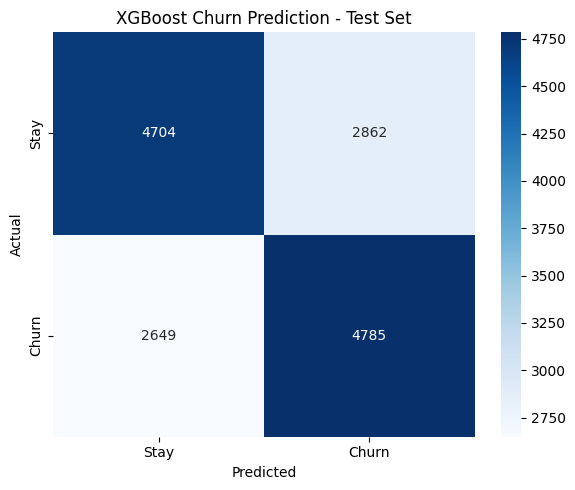


===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

        Stay       0.64      0.62      0.63      7566
       Churn       0.63      0.64      0.63      7434

    accuracy                           0.63     15000
   macro avg       0.63      0.63      0.63     15000
weighted avg       0.63      0.63      0.63     15000


SECTION 7A COMPLETED SUCCESSFULLY!


In [2]:

# ============================================================
# SECTION 7A: FINAL XGBOOST MODEL EVALUATION
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("===== XGBOOST TEST SET EVALUATION =====")

# 1. Verify we are using our held-out test set
assert X_test_processed.shape[0] == 15000
assert len(y_test) == 15000

# 2. Predict churn probabilities
y_test_prob = xgb_model.predict_proba(
    X_test_processed
)[:, 1]

# 3. Convert probabilities to predicted classes
threshold = 0.50
y_test_pred = (y_test_prob >= threshold).astype(int)

# 4. Calculate metrics
test_auc = roc_auc_score(y_test, y_test_prob)
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)

print("\n===== MODEL PERFORMANCE =====")
print("Test customers:", len(y_test))
print(
    "Validation ROC-AUC:",
    round(model_config["validation_roc_auc"], 4)
)
print(f"Test ROC-AUC: {test_auc:.4f}")
print(f"Accuracy: {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall: {test_recall:.4f}")
print(f"F1-score: {test_f1:.4f}")

# 5. Confusion matrix
cm = confusion_matrix(
    y_test, y_test_pred,
    labels=[0, 1]
)

print("\n===== CONFUSION MATRIX =====")
print(cm)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stay", "Churn"],
    yticklabels=["Stay", "Churn"]
)

plt.title("XGBoost Churn Prediction - Test Set")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# 6. Classification report
print("\n===== CLASSIFICATION REPORT =====")
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["Stay", "Churn"]
    )
)

print("\nSECTION 7A COMPLETED SUCCESSFULLY!")


The model achieved a test ROC-AUC of 0.6862, indicating moderate ability to distinguish customers who churn from those who remain.

The validation ROC-AUC was 0.6882, only 0.0020 higher than the test result. This indicates consistent performance across the two datasets, although it does not establish that every possible source of data leakage has been eliminated.



## Confusion Matrix Interpretation

The confusion matrix produced the following results:

| Actual outcome | Predicted Stay | Predicted Churn |
|---|---:|---:|
| Stay | 4,704 | 2,862 |
| Churn | 2,649 | 4,785 |

- **True Negatives (4,704):** Customers correctly predicted to remain.
- **True Positives (4,785):** Customers correctly predicted to churn.
- **False Positives (2,862):** Customers incorrectly flagged as likely to churn.
- **False Negatives (2,649):** Customers who churned but were not flagged.

These errors have different implications for Company A.

False positives may lead to unnecessary retention spending if the company provides incentives to customers who would have remained anyway.

False negatives represent missed opportunities to identify customers who might benefit from retention interventions.

However, identifying a likely churner does not establish that a retention intervention would successfully prevent churn.

### Bussiness Interpretation and Model Limitations

Our evaluation suggests that XGBoost provides a useful starting point for identifying higher-risk customers.

Nevertheless, an accuracy of 63.26% indicates that the model still makes substantial classification errors.

For this reason, Company A should not rely solely on a fixed classification threshold when deciding which customers to contact.

A more practical strategy may involve ranking customers by predicted churn probability and prioritizing outreach according to risk, customer value, intervention cost, and operational capacity.

The model's current performance does not establish that it is ready for deployment. Further validation, fairness monitoring, leakage checks, and controlled business testing would be required.

Comparison with a Simple Baseline

The test dataset contains 7,566 retained customers and 7,434 churned customers.

A baseline model that always predicts the majority class (stay) would achieve approximately 50.44% accuracy.

Our XGBoost model achieved 63.26% accuracy, an improvement of approximately 12.82 percentage points.

This demonstrates that the model captures predictive information beyond simply selecting the majority class.

 Conclusion

The XGBoost model performs better than the majority-class baseline and demonstrates moderate predictive ability on unseen test data.

The model provides evidence that historical customer information contains signals associated with future churn.

The next analysis will investigate whether customers with the highest predicted churn probabilities are more likely to churn than average, helping determine whether risk-based targeting could support Company A's retention strategy.



**7B Evaluate Targeted Customer Prioritization**

This is an additional analysis beyond the tutorial's basic accuracy and confusion matrix. I recommend it because it connects our model directly to the business proposal in Section 8.

Imagine Company A can only contact 10% or 20% of its customers.

Rather than predicting churn for everyone using a fixed 0.50 threshold, we can rank customers from highest to lowest predicted churn risk.

We want to investigate:
1. How many actual churners appear among the highest-risk customers?
2. Is the churn rate among these customers higher than the overall test-set rate?
3. How much better is our targeting than selecting customers without a predictive ranking?

In [3]:

# ============================================================
# SECTION 7B: CHURN TARGETING AND LIFT ANALYSIS
# ============================================================

import numpy as np
import pandas as pd

print("===== CUSTOMER TARGETING ANALYSIS =====")

# Actual outcomes and model risk scores
actual_churn = np.asarray(y_test)
risk_scores = np.asarray(y_test_prob)

# Sort from highest predicted churn risk to lowest
ranked_indices = np.argsort(
    -risk_scores,
    kind="stable"
)

# Overall churn rate in the test sample
overall_churn_rate = actual_churn.mean()
total_churners = int(actual_churn.sum())

results = []

# Evaluate fixed targeting proportions
for target_share in [0.10, 0.20, 0.30]:

    n_targeted = int(
        len(actual_churn) * target_share
    )

    top_indices = ranked_indices[:n_targeted]

    churners_found = int(
        actual_churn[top_indices].sum()
    )

    targeted_churn_rate = (
        churners_found / n_targeted
    )

    lift = (
        targeted_churn_rate / overall_churn_rate
    )

    capture_rate = (
        churners_found / total_churners
    )

    results.append({
        "Targeted customers": n_targeted,
        "Target share": f"{target_share:.0%}",
        "Actual churners found": churners_found,
        "Churn rate in group": round(
            targeted_churn_rate, 4
        ),
        "Lift": round(lift, 3),
        "Churners captured": round(
            capture_rate, 4
        )
    })

targeting_results = pd.DataFrame(results)

print("Total test customers:", len(actual_churn))
print("Actual churners:", total_churners)
print(
    "Overall test churn rate:",
    f"{overall_churn_rate:.2%}"
)

print("\n===== TARGETING RESULTS =====")
print(targeting_results.to_string(index=False))

print("\nSECTION 7B COMPLETED!")


===== CUSTOMER TARGETING ANALYSIS =====
Total test customers: 15000
Actual churners: 7434
Overall test churn rate: 49.56%

===== TARGETING RESULTS =====
 Targeted customers Target share  Actual churners found  Churn rate in group  Lift  Churners captured
               1500          10%                   1184               0.7893 1.593             0.1593
               3000          20%                   2176               0.7253 1.464             0.2927
               4500          30%                   3079               0.6842 1.381             0.4142

SECTION 7B COMPLETED!


**Business Interpretation — Customer Targeting**

The XGBoost model demonstrates an ability to concentrate customers with higher observed churn risk into smaller targeting groups. The top 10% highest-risk customers had an observed churn rate of 78.93%, compared with the overall test-set rate of 49.56%, producing a lift of 1.593.

Targeting the highest-risk 20% captured 29.27% of all actual churners in the test dataset. These results suggest that risk-based targeting could help Company A prioritize retention resources more effectively than random customer selection.

Nevertheless, the results establish predictive ranking performance, not the effectiveness of retention interventions. A controlled pilot, customer-value analysis, and cost-benefit assessment are needed before recommending full deployment.

**Questions to think about:**
- A baseline that always predicts the majority class would score around 0.5 here. Does your accuracy meaningfully beat that? If not, the model isn't adding evidence yet.
- Accuracy treats false positives and false negatives equally. Are they really equally costly for *your* proposal — flagging a stayer as a churner (wasted retention spend) versus missing a real churner (lost revenue)?
- What other metrics could you compute — AUC, precision, recall, F1? When would each be more informative than accuracy?
- If your accuracy looks suspiciously high, could a feature be leaking the target?

# 7.1 Feature importance

The purpose of this analysis is to identify which customer characteristics contribute most strongly to the trained XGBoost model's predictions.

We use **gain-based feature importance**, which measures the average improvement in the model's training objective when a feature is used for a tree split.

Our model was trained using 78 selected original features, expanded into 90 encoded features through preprocessing.

Feature importance helps identify the signals used by the model and can guide the development of Company A's customer-retention proposal.

However, feature importance does not establish causation, indicate whether a feature increases or decreases churn risk, or prove that changing a feature will prevent churn.

We will therefore interpret important features alongside the exploratory data analysis, business relevance, and feasibility of potential retention interventions.

**7.1A Calculating Our Feature Importance**

===== XGBOOST FEATURE IMPORTANCE =====
Total encoded features: 90
Features used in tree splits: 84

===== TOP 15 FEATURES BY GAIN =====
        Feature      Gain
        eqpdays 56.884254
hnd_webcap_WCMB 51.278549
   refurb_new_N 38.577881
         months 33.101513
       mou_Mean 19.098089
      hnd_price 18.622787
     asl_flag_N 18.099848
     change_mou 17.391584
       uniqsubs 16.179310
    totmrc_Mean 15.643866
         avgqty 14.356281
  mou_cvce_Mean 13.125963
         avgrev 12.521277
    vceovr_Mean 11.783966
         avgmou 11.638850


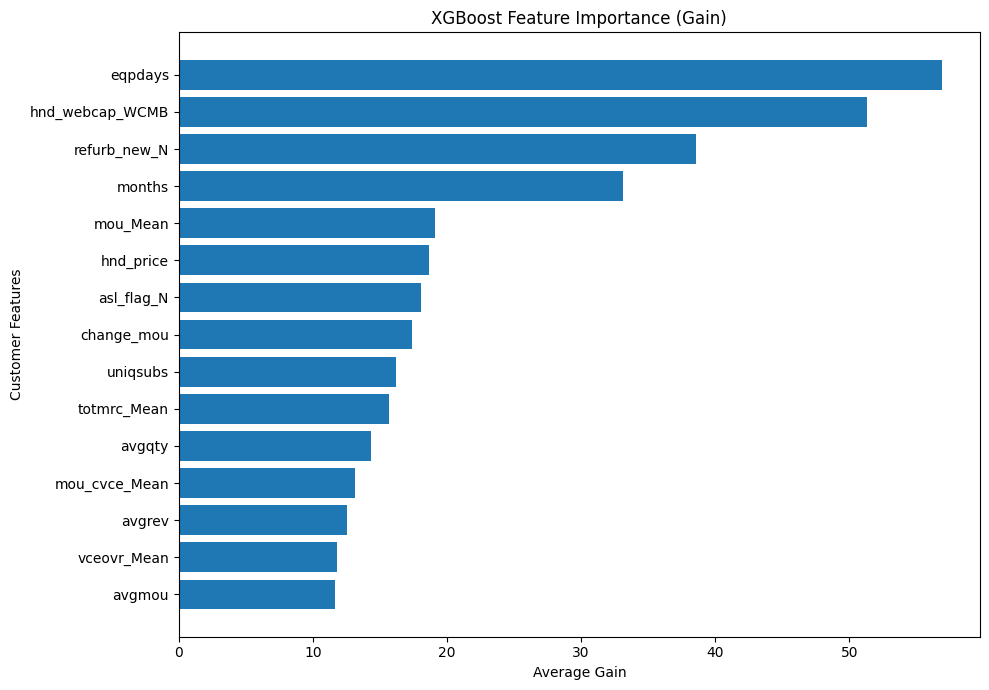


Feature importance table saved: True
Feature importance chart saved: True

SECTION 7.1A COMPLETED!


In [4]:

# ============================================================
# SECTION 7.1A: XGBOOST FEATURE IMPORTANCE (GAIN)
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("===== XGBOOST FEATURE IMPORTANCE =====")

# 1. Get feature names from fitted preprocessing
encoded_feature_names = preprocessor.get_feature_names_out()

# 2. Access the trained XGBoost model
booster = xgb_model.get_booster()

# 3. Get gain-based importance scores
gain_scores = booster.get_score(importance_type="gain")

# 4. Match model features to original encoded names
model_feature_names = booster.feature_names

if model_feature_names is None:
    model_feature_names = [
        f"f{i}" for i in range(len(encoded_feature_names))
    ]

assert len(model_feature_names) == len(encoded_feature_names)

feature_importance_df = pd.DataFrame({
    "Encoded feature": encoded_feature_names,
    "Gain": [
        gain_scores.get(name, 0.0)
        for name in model_feature_names
    ]
})

# 5. Simplify display names
feature_importance_df["Feature"] = (
    feature_importance_df["Encoded feature"]
    .str.replace(r"^(num|cat)__", "", regex=True)
)

# 6. Rank features
feature_importance_df = (
    feature_importance_df
    .sort_values("Gain", ascending=False)
    .reset_index(drop=True)
)

top_15_features = feature_importance_df.head(15)

print("Total encoded features:", len(encoded_feature_names))
print("Features used in tree splits:", len(gain_scores))

print("\n===== TOP 15 FEATURES BY GAIN =====")
print(
    top_15_features[["Feature", "Gain"]]
    .to_string(index=False)
)

# 7. Create the importance chart
fig, ax = plt.subplots(figsize=(10, 7))

plot_data = top_15_features.iloc[::-1]

ax.barh(
    plot_data["Feature"],
    plot_data["Gain"]
)

ax.set_title("XGBoost Feature Importance (Gain)")
ax.set_xlabel("Average Gain")
ax.set_ylabel("Customer Features")

plt.tight_layout()

# 8. Save results for the final assignment
output_dir = Path(
    "/content/drive/MyDrive/telecom/model_artifacts"
)

output_dir.mkdir(parents=True, exist_ok=True)

feature_importance_df.to_csv(
    output_dir / "section_7_1_feature_importance.csv",
    index=False
)

fig.savefig(
    output_dir / "section_7_1_feature_importance.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\nFeature importance table saved: True")
print("Feature importance chart saved: True")
print("\nSECTION 7.1A COMPLETED!")


#### Feature Importance — Business Interpretation

The XGBoost feature-importance analysis identified equipment age (`eqpdays`) as the strongest feature, with an average gain of 56.88. Other leading predictors included the encoded handset category `hnd_webcap_WCMB` (51.28), handset status `refurb_new_N` (38.58), customer tenure (`months`, 33.10), and average monthly usage (`mou_Mean`, 19.10).

These results suggest that **handset-related characteristics, customer tenure, and usage behavior are important signals in our churn prediction model**.

**1. Handset age and customer retention**

Equipment age is the highest-ranked feature. Earlier EDA showed that customers with equipment older than 730 days had a churn rate of 57.89%, compared with 41.78% among customers with equipment aged 0–180 days.

Company A could investigate a targeted handset-upgrade pilot for high-risk customers using older devices. The company would need to assess the cost of upgrades and whether they actually improve retention.

**2. Handset characteristics and service experience**

The importance of `hnd_webcap_WCMB` and `refurb_new_N` suggests that handset categories and device status contain useful predictive information.

Before developing specific interventions, Company A should confirm the meanings of these encoded categories using the dataset documentation. Potential actions include investigating handset compatibility, replacement requirements, and customer experience across device segments.

**3. Customer tenure**

Customer tenure (`months`) is another important feature. Although tenure itself cannot be changed directly, it can support segmentation and the timing of retention communication.

Company A could investigate whether customers at different stages of their relationship with the company respond differently to retention offers.

**4. Usage and engagement**

Average usage (`mou_Mean`) and usage change (`change_mou`) are also important predictors.

Company A could test proactive engagement for customers exhibiting declining usage, particularly when this pattern occurs alongside older handset age and high predicted churn risk.

**5. Proposed business direction**

The findings support a customer-retention strategy focused on:

- Prioritizing customers by predicted churn risk.
- Investigating handset-related interventions for eligible high-risk customers.
- Using changes in usage behavior as signals for proactive customer engagement.
- Considering customer value and intervention costs when prioritizing outreach.
- Measuring actual retention outcomes through a controlled pilot.

Our earlier targeting analysis showed that the highest-risk 10% of test customers had an observed churn rate of 78.93%, producing a targeting lift of 1.593.

This provides an evidence base for testing targeted retention interventions rather than contacting all customers indiscriminately.

**Limitations**

Feature importance measures how the trained model uses variables; it does not establish causation or the direction of their effect on churn. Correlated variables may also influence the resulting feature rankings.

The model's test ROC-AUC of 0.6862 indicates moderate predictive discrimination. Further validation, fairness checks, and controlled intervention testing would be required before operational deployment.

**Conclusion**

The feature-importance results indicate that handset-related characteristics and customer usage are promising areas for further investigation. Combined with the model's risk-ranking performance, these findings provide a foundation for developing an evidence-based retention proposal for Company A.

*Source: Original analysis of Company A's supplied Client and Record datasets. Methodology: R6–R8 in the References Register.*

---

#8.From Model to Proposal

### Business Objective

The objective of this section is to translate the results of our XGBoost churn prediction model into a practical customer-retention proposal for Company A.

The model achieved a test ROC-AUC of **0.6862**, indicating moderate predictive discrimination. More importantly, the highest-risk 10% of test customers had an observed churn rate of **78.93%**, compared with the overall test-set churn rate of **49.56%**. This represents a targeting lift of **1.593**.

These results suggest that risk-based targeting could help Company A concentrate retention resources on customers more likely to churn.

### Proposed Business Strategy

We propose evaluating a **Risk-Based Customer Retention Pilot**.

The pilot would use predicted churn risk to prioritize customers for appropriate retention outreach. Potential interventions include handset-related assistance, targeted upgrade offers, and proactive service engagement.

The feature-importance analysis identified equipment age, handset characteristics, customer tenure, and usage behavior as important predictive signals. These findings provide a basis for investigating relevant interventions, although they do not establish that any specific intervention will prevent churn.

### Expected Business Value

The proposal will assess potential financial value by combining:

- The number of customers eligible for outreach.
- The estimated revenue value of customers at risk.
- The cost of retention interventions.
- The incremental reduction in churn achieved by the intervention.
- The net financial benefit after campaign costs.

Financial calculations will distinguish observed dataset values from explicitly stated assumptions. The dataset's revenue currency and reporting period must also be verified before monetary estimates are interpreted.

### Validation Approach

Company A should test the proposed interventions through a controlled pilot with treatment and comparison groups.

The pilot will measure incremental retention, financial impact, operational feasibility, and relevant customer-experience outcomes before considering wider deployment.

*Source: Original analysis of Company A's Client and Record datasets. Industry research and methodological references are tracked separately in the References Register.*

**8.1 Examine Customer Revenue and Business Value**

In [6]:

# ============================================================
# SECTION 8.1: CUSTOMER REVENUE AND BUSINESS VALUE
# ============================================================

import numpy as np
import pandas as pd

print("===== CUSTOMER REVENUE ANALYSIS =====")

# 1. Build business analysis dataset
business_df = pd.DataFrame({
    "risk_score": np.asarray(y_test_prob),
    "actual_churn": np.asarray(y_test),
    "revenue": pd.to_numeric(
        X_test["rev_Mean"], errors="coerce"
    ).to_numpy()
})

# 2. Rank customers by predicted churn risk
business_df = (
    business_df
    .sort_values("risk_score", ascending=False, kind="stable")
    .reset_index(drop=True)
)

# 3. Identify top 10% highest-risk customers
top_10_count = int(len(business_df) * 0.10)

business_df["high_risk"] = False
business_df.loc[
    :top_10_count - 1, "high_risk"
] = True

# 4. Define high revenue using training data only
high_revenue_threshold = (
    X_train["rev_Mean"].quantile(0.75)
)

business_df["high_revenue"] = (
    business_df["revenue"] >= high_revenue_threshold
)

# 5. Summary of revenue data
print("\n===== REVENUE DATA QUALITY =====")
print("Test customers:", len(business_df))
print("Missing revenue:", business_df["revenue"].isna().sum())
print("Negative revenue:", (business_df["revenue"] < 0).sum())

print("\n===== REVENUE SUMMARY =====")
print("Overall mean:", round(business_df["revenue"].mean(), 2))
print("Overall median:", round(business_df["revenue"].median(), 2))
print("High-revenue threshold:", round(high_revenue_threshold, 2))

# 6. Compare high-risk and other customers
print("\n===== REVENUE BY RISK GROUP =====")

risk_summary = business_df.groupby("high_risk").agg(
    customers=("actual_churn", "size"),
    churn_rate=("actual_churn", "mean"),
    average_revenue=("revenue", "mean"),
    median_revenue=("revenue", "median")
)

print(risk_summary.round(4))

# 7. Examine high-risk, high-revenue customers
high_risk_high_value = business_df[
    business_df["high_risk"]
    & business_df["high_revenue"]
]

print("\n===== HIGH-RISK, HIGH-REVENUE GROUP =====")

print("Customers:", len(high_risk_high_value))

print(
    "Observed churn rate:",
    f"{high_risk_high_value['actual_churn'].mean():.2%}"
)

print(
    "Average revenue:",
    round(high_risk_high_value["revenue"].mean(), 2)
)

print(
    "Median revenue:",
    round(high_risk_high_value["revenue"].median(), 2)
)

print("\nSECTION 8.1 COMPLETED!")


===== CUSTOMER REVENUE ANALYSIS =====

===== REVENUE DATA QUALITY =====
Test customers: 15000
Missing revenue: 51
Negative revenue: 1

===== REVENUE SUMMARY =====
Overall mean: 58.54
Overall median: 47.73
High-revenue threshold: 70.74

===== REVENUE BY RISK GROUP =====
           customers  churn_rate  average_revenue  median_revenue
high_risk                                                        
False          13500      0.4630          59.0988         48.2475
True            1500      0.7893          53.3992         43.8167

===== HIGH-RISK, HIGH-REVENUE GROUP =====
Customers: 312
Observed churn rate: 74.36%
Average revenue: 111.7
Median revenue: 97.59

SECTION 8.1 COMPLETED!


###8.1 Business Interpretation

The revenue analysis demonstrates why Company A should consider customer value alongside predicted churn risk when designing a retention strategy.

Among the 15,000 test customers, the overall average revenue was 58.54, while the median was 47.73. The high-revenue threshold, defined using the 75th percentile of training-set revenue, was 70.74.

The highest-risk 10% of customers had an observed churn rate of 78.93% and average revenue of 53.40. In comparison, the remaining customers had an observed churn rate of 46.30% and average revenue of 59.10.

This demonstrates that the customers with the highest churn risk are not necessarily those with the highest average revenue.

**High-Risk, High-Revenue Customers**

We identified 312 customers who belonged to both the highest-risk 10% and the high-revenue category.

This group had:

- An observed churn rate of 74.36%.
- An average revenue of 111.70.
- A median revenue of 97.59.

These findings suggest that a combined risk-and-value targeting strategy deserves investigation.

**Business Recommendation**

Company A should evaluate a targeted retention pilot that considers both predicted churn risk and customer financial value.

Potential interventions include proactive customer-service engagement, handset-related support, and carefully selected retention offers.

The choice of intervention should depend on the customer's needs, expected retention benefit, and intervention cost.

**Limitations**

The analysis identified 51 missing revenue values and one negative revenue value. These must be handled appropriately when estimating financial outcomes.

The dataset does not establish the revenue currency or reporting period. Revenue is also not equivalent to profit.

Furthermore, the test dataset's churn rate may not represent Company A's actual customer population.

The findings demonstrate revenue exposure and predictive associations, not the causal effectiveness of retention interventions.

**Conclusion**

Combining churn risk with customer value provides a more commercially relevant foundation for Company A's proposed retention strategy than relying on churn probability alone.

*Source: Original analysis of Company A's supplied Client and Record datasets.*

**8.2 Quantify the Financial Impact**

In [7]:

# ============================================================
# SECTION 8.2: ILLUSTRATIVE FINANCIAL IMPACT ANALYSIS
# ============================================================

import pandas as pd
import numpy as np

print("===== FINANCIAL IMPACT SCENARIOS =====")

# IMPORTANT: All values below are illustrative assumptions.
# Currency and revenue reporting period are not confirmed.

cost_per_customer = 5.0
contribution_margin = 0.40
revenue_periods = 3

# Assumed ABSOLUTE churn reductions
churn_reductions = [0.03, 0.05, 0.10]

# Prepare financial analysis using valid nonnegative revenue
valid_revenue = business_df["revenue"].where(
    business_df["revenue"] >= 0
)

segments = {
    "Top 10% risk": business_df["high_risk"],
    "High risk + high revenue": (
        business_df["high_risk"]
        & business_df["high_revenue"]
    )
}

financial_results = []

for segment_name, mask in segments.items():

    segment = business_df.loc[mask]
    n_customers = len(segment)

    avg_revenue = valid_revenue.loc[mask].mean()

    campaign_cost = (
        n_customers * cost_per_customer
    )

    for reduction in churn_reductions:

        additional_retained = (
            n_customers * reduction
        )

        contribution_retained = (
            additional_retained
            * avg_revenue
            * revenue_periods
            * contribution_margin
        )

        net_benefit = (
            contribution_retained - campaign_cost
        )

        financial_results.append({
            "Segment": segment_name,
            "Customers": n_customers,
            "Churn reduction": f"{reduction:.0%} pp",
            "Additional retained": round(
                additional_retained, 1
            ),
            "Gross contribution benefit": round(
                contribution_retained, 2
            ),
            "Campaign cost": round(
                campaign_cost, 2
            ),
            "Net benefit": round(
                net_benefit, 2
            )
        })

financial_df = pd.DataFrame(financial_results)

print("\n===== ILLUSTRATIVE ASSUMPTIONS =====")
print("Cost per customer:", cost_per_customer)
print("Contribution margin:", contribution_margin)
print("Revenue periods:", revenue_periods)

print("\n===== SCENARIO RESULTS =====")
print(financial_df.to_string(index=False))

print("\nSECTION 8.2 COMPLETED!")


===== FINANCIAL IMPACT SCENARIOS =====

===== ILLUSTRATIVE ASSUMPTIONS =====
Cost per customer: 5.0
Contribution margin: 0.4
Revenue periods: 3

===== SCENARIO RESULTS =====
                 Segment  Customers Churn reduction  Additional retained  Gross contribution benefit  Campaign cost  Net benefit
            Top 10% risk       1500           3% pp                 45.0                     2883.56         7500.0     -4616.44
            Top 10% risk       1500           5% pp                 75.0                     4805.93         7500.0     -2694.07
            Top 10% risk       1500          10% pp                150.0                     9611.85         7500.0      2111.85
High risk + high revenue        312           3% pp                  9.4                     1254.59         1560.0      -305.41
High risk + high revenue        312           5% pp                 15.6                     2090.98         1560.0       530.98
High risk + high revenue        312          10% pp 

### 8.2 Financial Impact and Business Interpretation

The financial scenario analysis evaluated two potential customer-retention targeting strategies: the highest-risk 10% of customers (1,500 customers) and the high-risk, high-revenue segment (312 customers).

The analysis used illustrative assumptions of 5 revenue-currency units per contacted customer, a 40% contribution margin, and a retention-value horizon of three revenue periods.

Three hypothetical absolute churn reductions were examined: 3, 5, and 10 percentage points.

**Strategy 1: Targeting the Highest-Risk 10%**

Targeting all 1,500 high-risk customers would incur a campaign cost of 7,500 units.

Under a 5-percentage-point churn reduction, the strategy would generate an estimated net loss of 2,694.07 units. A 10-percentage-point reduction would produce an estimated positive net benefit of 2,111.85 units.

This suggests that broad high-risk targeting may require substantial intervention effectiveness to justify its cost.

**Strategy 2: Targeting High-Risk, High-Revenue Customers**

Targeting the 312 high-risk, high-revenue customers would incur a campaign cost of 1,560 units.

Under a 5-percentage-point reduction in churn, the estimated net benefit would be 530.98 units. Under a 10-percentage-point reduction, it would increase to 2,621.95 units.

These results suggest that combining predicted churn risk with customer revenue may offer more favorable financial economics under the stated assumptions.

**Business Recommendation**

Company A should investigate a limited retention pilot focused initially on eligible high-risk, high-revenue customers.

The pilot should assess appropriate interventions, such as proactive customer-service engagement, handset-related support, and carefully controlled retention offers.

**Financial Limitations**

All financial outcomes are illustrative rather than observed.

The intervention cost, contribution margin, and incremental churn reduction have not been verified using Company A's operational or experimental data. The revenue currency and reporting period are also unspecified.

The assumed intervention cost must cover all relevant campaign expenses; otherwise, the net-benefit calculations may overstate profitability.

The analysis estimates expected customer retention rather than guaranteeing that a particular number of customers will be saved. It also assumes that the average revenue of retained customers is representative of those whose churn is actually prevented.

A controlled pilot is required to measure incremental retention effects and validate the financial assumptions before full deployment.

**Conclusion**

The scenario analysis supports investigating a combined risk-and-value targeting strategy. Under the current assumptions, targeting high-risk, high-revenue customers appears financially more attractive than broad high-risk targeting.

This result provides a foundation for a controlled business experiment, rather than evidence of guaranteed financial returns.

*Source: Original analysis of Company A's supplied datasets. Financial assumptions are illustrative and not externally sourced.*

**8.3 Calculate the Break-Even Point**

In [8]:

# ============================================================
# SECTION 8.3: BREAK-EVEN RETENTION ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

print("===== RETENTION BREAK-EVEN ANALYSIS =====")

# Use the same illustrative financial assumptions
# established in Section 8.2.

break_even_results = []

for segment_name, mask in segments.items():

    segment = business_df.loc[mask]

    n_customers = len(segment)

    avg_revenue = valid_revenue.loc[mask].mean()

    campaign_cost = n_customers * cost_per_customer

    # Contribution value of saving one customer
    value_per_retained_customer = (
        avg_revenue
        * revenue_periods
        * contribution_margin
    )

    # Expected additional retained customers
    # needed to recover the campaign cost
    required_retained = (
        campaign_cost / value_per_retained_customer
    )

    # Absolute reduction in churn required
    break_even_reduction = (
        required_retained / n_customers
    )

    break_even_results.append({
        "Segment": segment_name,
        "Customers": n_customers,
        "Campaign cost": round(campaign_cost, 2),
        "Value per retained customer": round(
            value_per_retained_customer, 2
        ),
        "Expected additional retained needed": round(
            required_retained, 2
        ),
        "Break-even reduction (pp)": round(
            break_even_reduction * 100, 2
        )
    })

break_even_df = pd.DataFrame(break_even_results)

print("\n===== BREAK-EVEN RESULTS =====")
print(break_even_df.to_string(index=False))

# Save results for recovery and presentation
output_dir = Path(
    "/content/drive/MyDrive/telecom/model_artifacts"
)

output_dir.mkdir(parents=True, exist_ok=True)

break_even_df.to_csv(
    output_dir / "section_8_break_even.csv",
    index=False
)

financial_df.to_csv(
    output_dir / "section_8_financial_scenarios.csv",
    index=False
)

print("\nBreak-even results saved: True")
print("Financial scenarios saved: True")
print("\nSECTION 8.3 COMPLETED!")


===== RETENTION BREAK-EVEN ANALYSIS =====

===== BREAK-EVEN RESULTS =====
                 Segment  Customers  Campaign cost  Value per retained customer  Expected additional retained needed  Break-even reduction (pp)
            Top 10% risk       1500         7500.0                        64.08                               117.04                       7.80
High risk + high revenue        312         1560.0                       134.04                                11.64                       3.73

Break-even results saved: True
Financial scenarios saved: True

SECTION 8.3 COMPLETED!


### 8.3 Break-Even Analysis and Business Interpretation

The break-even analysis calculated the minimum reduction in customer churn required to recover the costs of two proposed retention strategies.

Targeting the highest-risk 10% of customers requires an estimated **7.80-percentage-point reduction in churn** to break even. In comparison, targeting high-risk, high-revenue customers requires a smaller reduction of **3.73 percentage points**.

This difference arises because the high-risk, high-revenue segment has a higher estimated contribution value per retained customer.

**Business Recommendation**

Company A should prioritize investigating the high-risk, high-revenue segment through a controlled retention pilot.

Under the illustrative financial assumptions, a five-percentage-point reduction in churn would exceed the smaller segment's break-even requirement, but would not be sufficient for the broader high-risk segment.

**Limitations**

The break-even thresholds depend on assumed intervention costs, contribution margins, and revenue retention periods. They do not represent measured intervention effects or guaranteed returns.

Before scaling the strategy, Company A must verify these assumptions and determine whether the intervention produces an incremental reduction in churn compared with normal business operations.

**Conclusion**

The analysis suggests that value-conscious customer targeting may deliver more favorable retention economics than broad risk-based targeting. The next step is to design a controlled pilot to test this hypothesis.

*Source: Original financial scenario analysis using Company A's supplied data and explicitly stated illustrative assumptions.*

**8.4 Retention Pilot Design**

### 8.4 Proposed Customer-Retention Pilot

**Pilot Objective**

Evaluate whether a risk-based and revenue-conscious retention intervention can reduce customer churn sufficiently to generate positive incremental financial value.

**Target Customers**

The pilot will prioritize eligible customers identified by the XGBoost model as having high churn risk and relatively high revenue.

The historical analysis identified 312 such customers within the test sample, with an observed churn rate of 74.36% and average revenue of 111.70. These figures provide preliminary evidence for investigating this segment.

**Intervention Design**

Company A should investigate a proactive customer-engagement program combining:

1. Customer-service consultations to identify unresolved problems.
2. Handset-related support or upgrade eligibility assessments.
3. Appropriate service-plan reviews where customer needs indicate a possible mismatch.

Interventions should be relevant to customer needs, with costs recorded individually. Customers should retain access to normal customer support.

**Experimental Evaluation**

Eligible customers will be randomly assigned to a treatment group and a control group.

The treatment group will be offered the proposed intervention, while the control group will continue receiving standard service.

The primary analysis will compare churn rates between groups based on their original assignment.

**Primary Business KPIs**

- Absolute reduction in churn, measured in percentage points.
- Incremental customers retained through the intervention.
- Actual campaign cost per targeted customer.
- Incremental contribution generated by retention.
- Net financial benefit after campaign costs.

Secondary measures will include customer satisfaction, intervention participation, and operational feasibility.

**Financial Success Criterion**

Under the illustrative assumptions from Section 8.3, the high-risk, high-revenue strategy requires an absolute churn reduction of approximately 3.73 percentage points to break even.

This figure is an initial financial benchmark rather than a statistically validated success threshold.

**Risks and Limitations**

The pilot must account for uncertainty in treatment effectiveness, intervention costs, customer response, and the generalizability of historical model results.

A statistical power calculation is needed before determining the pilot sample size. The company must also confirm the revenue currency, reporting period, and contribution margin.

**Recommendation**

Company A should conduct a sufficiently powered controlled pilot before considering wider deployment. Expansion should depend on evidence of incremental retention, acceptable customer experience, and positive financial value.

*Sources: Original Company A analysis; J-PAL and World Bank randomized-evaluation guidance (R9–R10).*

**8.5 Pilot Sample Size and Feasibility**

In [9]:

# ============================================================
# SECTION 8.5: RETENTION PILOT SAMPLE SIZE ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

print("===== RETENTION PILOT SAMPLE SIZE ANALYSIS =====")

# 1. Historical churn rate in target segment
pilot_segment = business_df.loc[
    business_df["high_risk"]
    & business_df["high_revenue"]
]

baseline_churn = float(
    pilot_segment["actual_churn"].mean()
)

# 2. Retrieve our financial break-even threshold
break_even_pp = float(
    break_even_df.loc[
        break_even_df["Segment"] == "High risk + high revenue",
        "Break-even reduction (pp)"
    ].iloc[0]
)

# 3. Statistical assumptions
alpha = 0.05
power = 0.80
allocation_ratio = 1.0
incomplete_followup = 0.10

effect_scenarios = [
    ("Break-even effect", break_even_pp / 100),
    ("Moderate effect", 0.05),
    ("Larger effect", 0.10)
]

power_analysis = NormalIndPower()

results = []

# 4. Calculate sample sizes
for scenario, reduction in effect_scenarios:

    expected_treatment_churn = (
        baseline_churn - reduction
    )

    effect_size = abs(
        proportion_effectsize(
            baseline_churn,
            expected_treatment_churn
        )
    )

    sample_per_group = power_analysis.solve_power(
        effect_size=effect_size,
        alpha=alpha,
        power=power,
        ratio=allocation_ratio,
        alternative="two-sided"
    )

    required_per_group = int(
        np.ceil(sample_per_group)
    )

    # Increase enrollment for 10% incomplete follow-up
    adjusted_per_group = int(
        np.ceil(
            required_per_group
            / (1 - incomplete_followup)
        )
    )

    results.append({
        "Scenario": scenario,
        "Churn reduction (pp)": round(
            reduction * 100, 2
        ),
        "Expected treatment churn (%)": round(
            expected_treatment_churn * 100, 2
        ),
        "Required per group": required_per_group,
        "Required total": required_per_group * 2,
        "Total with 10% allowance": adjusted_per_group * 2
    })

sample_size_df = pd.DataFrame(results)

# 5. Display results
print("\n===== HISTORICAL BASELINE =====")
print("Historical segment customers:", len(pilot_segment))
print(f"Baseline churn rate: {baseline_churn:.2%}")

print("\n===== STATISTICAL ASSUMPTIONS =====")
print("Significance level:", alpha)
print("Statistical power:", power)
print("Treatment/control allocation: 50/50")
print("Incomplete follow-up allowance: 10%")

print("\n===== SAMPLE SIZE RESULTS =====")
print(sample_size_df.to_string(index=False))

# 6. Save results to Google Drive
output_dir = Path(
    "/content/drive/MyDrive/telecom/model_artifacts"
)

output_dir.mkdir(parents=True, exist_ok=True)

sample_size_path = (
    output_dir / "section_8_pilot_sample_size.csv"
)

sample_size_df.to_csv(
    sample_size_path,
    index=False
)

print("\nSample size analysis saved:", sample_size_path.is_file())
print("\nSECTION 8.5 COMPLETED!")


===== RETENTION PILOT SAMPLE SIZE ANALYSIS =====

===== HISTORICAL BASELINE =====
Historical segment customers: 312
Baseline churn rate: 74.36%

===== STATISTICAL ASSUMPTIONS =====
Significance level: 0.05
Statistical power: 0.8
Treatment/control allocation: 50/50
Incomplete follow-up allowance: 10%

===== SAMPLE SIZE RESULTS =====
         Scenario  Churn reduction (pp)  Expected treatment churn (%)  Required per group  Required total  Total with 10% allowance
Break-even effect                  3.73                         70.63                2248            4496                      4996
  Moderate effect                  5.00                         69.36                1268            2536                      2818
    Larger effect                 10.00                         64.36                 332             664                       738

Sample size analysis saved: True

SECTION 8.5 COMPLETED!


###8.5 Pilot Sample Size and Feasibility Interpretation

The purpose of this analysis was to determine the sample size required to reliably evaluate the proposed customer-retention intervention.

Using a historical baseline churn rate of 74.36% among high-risk, high-revenue customers, we calculated sample-size requirements under three hypothetical intervention-effect scenarios.

The calculations assumed 80% statistical power, a 5% two-sided significance level, equal treatment and control groups, and a 10% allowance for incomplete follow-up.

**Sample Size Findings**

- **3.73-percentage-point churn reduction:** Approximately 4,996 customers, including the follow-up allowance.
- **5-percentage-point churn reduction:** Approximately 2,818 customers, including the follow-up allowance.
- **10-percentage-point churn reduction:** Approximately 738 customers, including the follow-up allowance.

The results demonstrate that smaller intervention effects require substantially larger samples to detect reliably.

**Business Feasibility**

Our historical test dataset identified 312 high-risk, high-revenue customers. This is insufficient on its own to support the planned randomized trial at the calculated sample sizes.

However, the historical test group is not the complete operational customer population. The actual number of eligible customers available for recruitment remains unknown.

Company A should first establish the number of eligible high-risk, high-revenue customers across its operational customer base.

If sufficient customers are available, the company could conduct a randomized pilot designed to detect an economically meaningful reduction in churn.

If recruitment capacity is limited, the company should consider extending recruitment across additional eligible cohorts or conducting a smaller feasibility study before a definitive effectiveness trial.

**Business Recommendation**

The preferred approach is a staged retention program:

1. Verify the operational population eligible for risk-and-value targeting.
2. Validate baseline churn rates and historical customer-revenue information.
3. Test the feasibility and cost of delivering the proposed interventions.
4. Conduct a sufficiently powered randomized trial when practical.
5. Expand the intervention only if the evidence supports positive incremental financial value and acceptable customer outcomes.

**Limitations**

The sample-size calculations depend on an estimated historical churn rate and hypothetical treatment effects. The future eligible population may have a different baseline churn rate.

The calculations also use a conventional two-proportion statistical test and assume independent observations. They should be reviewed if the experimental design, assignment method, or follow-up conditions differ.

The sample sizes indicate the approximate scale of a study needed to detect the specified effects; they do not guarantee statistically significant findings.

**Conclusion**

The sample-size analysis demonstrates that the proposed retention strategy requires careful experimental planning.

The financial analysis supports investigating high-risk, high-revenue targeting, but Company A must confirm operational feasibility and demonstrate an incremental retention benefit before recommending full deployment.

*Sources: Original Company A analysis; R9 — J-PAL randomized-evaluation methodology; R11 — statsmodels statistical-power methodology.*

###  8.6 — Implementation Roadmap, KPIs, Risks and Final Business Recommendation

#### 1. Proposed Business Recommendation

Based on our exploratory analysis, machine-learning results, customer-targeting analysis, and illustrative financial scenarios, we recommend that Company A investigate a **staged, risk-and-value-based customer-retention program**.

The program would use XGBoost churn-risk predictions alongside customer revenue information to prioritize eligible customers for retention interventions.

The initial focus should be on high-risk, high-revenue customers because this segment demonstrated potentially more favorable retention economics under our stated assumptions.

The recommendation is to conduct a controlled pilot, not to deploy the strategy immediately across the entire customer base.

#### 2. Implementation Roadmap

| Phase | Main activities | Deliverables |
|---|---|---|
| Phase 1: Preparation | Confirm customer eligibility, revenue definitions, intervention costs, and data governance | Approved pilot design and financial assumptions |
| Phase 2: Targeting | Apply the saved model, identify eligible high-risk/high-revenue customers, and randomly assign treatment and control groups | Targeting list and randomized allocation |
| Phase 3: Intervention | Offer relevant service support, handset-related assistance, or plan reviews; record intervention delivery and costs | Intervention and operational records |
| Phase 4: Evaluation | Compare churn and financial outcomes between the randomized groups | Experimental evaluation report |
| Phase 5: Decision | Review effectiveness, financial returns, uncertainty, and customer experience | Decision to expand, revise, or discontinue |

The implementation schedule should be agreed with Company A's operational teams.

#### 3. Key Performance Indicators

The proposed program should monitor the following KPIs.

| KPI | Measurement | Business purpose |
|---|---|---|
| Churn rate | Customers who churn / customers in each randomized group | Measure retention outcomes |
| Incremental churn reduction | Control churn rate minus treatment churn rate | Estimate the intervention's effect |
| Incremental customers retained | Estimated reduction in churn multiplied by the eligible population | Quantify retention impact |
| Campaign cost | Total intervention and operational expenditure | Monitor spending |
| Net financial benefit | Incremental retained contribution minus incremental campaign costs | Evaluate financial value |
| Return on investment | Net benefit / campaign cost | Evaluate financial efficiency |
| Customer satisfaction | Consistent customer-experience measurement | Monitor service quality |

The primary evaluation should compare customers according to their original randomized assignment, regardless of whether they accepted an offer.

Financial results should account for the actual costs and contribution value of retention. Statistical confidence intervals should accompany the estimated treatment effect.

#### 4. Financial Decision Criteria

Our illustrative financial analysis identified a break-even churn reduction of:

- **7.80 percentage points** when targeting the highest-risk 10%.
- **3.73 percentage points** when targeting high-risk, high-revenue customers.

For the proposed high-risk, high-revenue strategy, a five-percentage-point incremental reduction in churn would exceed the estimated break-even threshold under our assumptions.

The sample-size analysis indicated that approximately 2,818 customers, including a 10% incomplete-follow-up allowance, would be needed to design a randomized trial with 80% power to detect a five-percentage-point difference.

A smaller effect of 3.73 percentage points would require approximately 4,996 customers under the same assumptions.

Company A must confirm sufficient recruitment capacity before selecting the final trial size.

These financial and statistical thresholds should be revised using actual operational data.

#### 5. Risks and Mitigation Strategies

| Risk | Potential consequence | Recommended mitigation |
|---|---|---|
| Model prediction errors | Customers may be incorrectly prioritized | Monitor model performance and use a controlled pilot |
| Intervention ineffectiveness | No measurable reduction in churn | Compare randomized treatment and control groups |
| Unexpected campaign costs | Financial losses | Track actual intervention and operational expenses |
| Revenue uncertainty | Incorrect financial projections | Verify revenue periods, currency, and contribution margins |
| Limited eligible population | Insufficient statistical power | Check recruitment feasibility before launching |
| Data leakage or changing customer behavior | Unreliable predictions | Validate feature timing and monitor performance over time |
| Customer privacy or unfair treatment | Compliance and reputational risks | Apply privacy safeguards, access controls, and fairness monitoring |
| Inappropriate retention offers | Poor customer experience | Ensure offers are relevant, transparent, and voluntary |

#### 6. Expected Business Benefits

If the proposed intervention proves effective and financially worthwhile, Company A may achieve:

- More efficient allocation of customer-retention resources.
- Improved identification of customers at risk of leaving.
- More focused customer-service and handset-related interventions.
- Better alignment of retention spending with customer financial value.
- Stronger evidence for future customer-retention investment decisions.

These are potential benefits, not outcomes demonstrated by the historical dataset.

#### 7. Monitoring and Expansion Decision

After the pilot, Company A should assess whether:

1. The intervention reduced churn compared with standard service.
2. The estimated incremental financial value exceeded actual intervention costs.
3. Statistical uncertainty is sufficiently small to support a business decision.
4. Customer experience and fairness outcomes remained acceptable.
5. The intervention can be delivered consistently at greater scale.

If these conditions are adequately supported, Company A may consider a phased expansion with continued monitoring.

If results are inconclusive, the company should improve its intervention design, assess recruitment feasibility, or conduct further testing instead of assuming the program is effective.

#### 8. Final Business Recommendation

Our findings support investigating a targeted customer-retention strategy that combines predicted churn risk with customer revenue value.

The XGBoost model achieved a test ROC-AUC of 0.6862, and the highest-risk 10% of customers demonstrated a targeting lift of 1.593.

The financial scenarios suggest that selective targeting of high-risk, high-revenue customers could be more attractive than broader high-risk targeting under the specified assumptions.

However, the predictive model identifies risk rather than proving that customers can be retained through intervention.

**We therefore recommend that Company A validate the proposed program through a sufficiently powered randomized pilot, using incremental retention and net financial contribution as the primary business decision criteria.**

This approach converts our machine-learning evidence into an actionable, measurable, and financially accountable business proposal.

*Sources: Original analysis of Company A's Client and Record datasets; illustrative financial assumptions; randomized-evaluation and statistical-power methods referenced in R9–R11.*

#9.Conclusion

### 9.1 Project Summary

This project investigated customer churn at Company A using exploratory data analysis, machine learning, and business-focused financial evaluation.

The objective was not simply to predict which customers might leave, but to develop an actionable and measurable customer-retention recommendation supported by data.

Our analysis examined 100,000 customer records and developed an XGBoost classification model using customer usage, handset characteristics, revenue-related information, and other selected predictors.

### 9.2 Key Findings

**1. Customer churn prediction**

The final XGBoost model achieved:

| Evaluation Metric | Result |
|---|---:|
| Test ROC-AUC | 0.6862 |
| Accuracy | 63.26% |
| Precision | 62.57% |
| Recall | 64.37% |
| F1-score | 63.46% |

These results indicate moderate predictive discrimination. The model provides useful information for prioritizing customers but is not sufficiently accurate to guarantee individual churn outcomes.

**2. Risk-based customer targeting**

The highest-risk 10% of customers had an observed churn rate of 78.93%, compared with the overall test-set churn rate of 49.56%.

This produced a targeting lift of **1.593**, demonstrating that the model concentrated actual churners into a relatively small customer group.

**3. Important churn predictors**

Feature-importance analysis identified equipment age (`eqpdays`) as the strongest predictive feature. Other leading signals included handset characteristics, customer tenure, and average usage.

These findings suggest that handset-related customer experiences and engagement patterns deserve further investigation.

**4. Combining customer risk with financial value**

Among the 15,000 test customers, we identified 312 customers belonging to both the highest-risk 10% and the high-revenue category.

This group had an observed churn rate of 74.36% and average revenue of 111.70 in unspecified revenue-currency units.

The findings demonstrate that churn risk and customer financial value should be considered together when evaluating retention priorities.

### 9.3 Financial Impact

Our illustrative financial model compared broad high-risk targeting with selective high-risk, high-revenue targeting.

Under assumptions of an intervention cost of 5 units per contacted customer, a 40% contribution margin, and three revenue periods:

- Broad high-risk targeting required a **7.80-percentage-point churn reduction** to break even.
- High-risk, high-revenue targeting required a **3.73-percentage-point churn reduction** to break even.
- A hypothetical five-percentage-point reduction among the 312 high-risk, high-revenue customers generated an estimated **net benefit of 530.98 units**.

These figures are scenario estimates, not measured campaign outcomes.

The analysis suggests that selective targeting may offer better financial economics under the stated assumptions.

### 9.4 Final Business Recommendation

**We recommend that Company A investigate a staged, risk-and-value-based customer-retention program.**

The company should:

1. Identify eligible customers using predicted churn risk and revenue information.
2. Investigate appropriate retention interventions, including proactive service engagement and handset-related support.
3. Evaluate the interventions through a randomized treatment-and-control pilot.
4. Measure incremental churn reduction, actual costs, customer experience, and financial returns.
5. Expand the program only when results support positive incremental business value.

For an illustrative five-percentage-point intervention effect, our sample-size analysis estimated a requirement of approximately 2,818 participants, including an allowance for incomplete follow-up.

The actual eligible population and final experimental design must be confirmed before implementation.

### 9.5 Limitations

Several limitations must be acknowledged.

- The dataset's approximately balanced churn classes may not represent Company A's operational churn rate.
- Model predictions identify associations and predictive signals, not causal relationships.
- Feature importance does not prove that changing a feature will prevent churn.
- Revenue currency, reporting period, contribution margins, and intervention costs require verification.
- Financial scenarios use hypothetical intervention effects rather than observed experimental evidence.
- The model requires further assessment for data leakage, temporal stability, fairness, and operational readiness.
- The availability of enough eligible customers for a sufficiently powered pilot remains unknown.

### 9.6 Final Conclusion

This project demonstrates how customer data and machine learning can support more focused retention decision-making.

The XGBoost model achieved moderate predictive performance and identified meaningful differences in churn concentration across customer-risk groups.

Combining these predictions with customer revenue information produced a more commercially relevant retention proposal than relying on model accuracy alone.

**The central recommendation is to test targeted retention interventions among high-risk, high-revenue customers and evaluate their incremental financial impact before wider implementation.**

This approach connects predictive analytics with measurable business objectives, financial accountability, and evidence-based decision-making.

### Sources and References

- **Primary source:** Company A's supplied `Client.csv` and `Record.csv` datasets.
- **Modeling and methodological sources:** XGBoost, scikit-learn, statsmodels, J-PAL, and World Bank DIME, as documented in the References Register.
- **Industry research:** External publications recorded in references R1–R5, subject to final bibliographic verification.
- **Financial estimates:** Original scenario calculations using explicitly stated illustrative assumptions.

The complete References Register and any AI-assistance disclosure required by the assignment should be included in the final submission.

# 10.References Register — Technical and Evaluation Methodology

The following references supplement the industry research sources R1–R5 documented earlier in this notebook.

**[R6] XGBoost Developers — Feature Importance and Model Training**

XGBoost Developers. (n.d.). *Python API Reference*. XGBoost Documentation.

URL: https://xgboost.readthedocs.io/en/stable/python/python_api.html

**Purpose:** Supports the XGBoost classification methodology, early stopping, and gain-based feature importance used in Sections 6 and 7.1.

---

**[R7] Scikit-learn Developers — Preprocessing**

Scikit-learn Developers. (n.d.). *ColumnTransformer*. Scikit-learn Documentation.

URL: https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html

**Purpose:** Supports the numerical and categorical preprocessing pipeline and retrieval of encoded feature names used in Sections 5, 6, and 7.1.

---

**[R8] Scikit-learn Developers — Feature Importance Interpretation**

Scikit-learn Developers. (n.d.). *Permutation Feature Importance*. Scikit-learn User Guide.

URL: https://scikit-learn.org/stable/modules/permutation_importance.html

**Purpose:** Provides methodological context for interpreting feature importance and understanding the effects of correlated predictors. Permutation importance was not calculated in this project; our reported rankings use XGBoost gain.

---

**[R9] J-PAL — Randomized Evaluation Design**

Gibson, M., & Sautmann, A. (n.d.). *The Elements of a Randomized Evaluation*. Abdul Latif Jameel Poverty Action Lab (J-PAL).

URL: https://www.povertyactionlab.org/resource/elements-randomized-evaluation

**Purpose:** Supports the proposed treatment-and-control experiment, outcome measurement, and evaluation of intervention effectiveness in Section 8.

---

**[R10] World Bank DIME — Experimental Study Design**

World Bank, Development Impact Evaluation (DIME). (n.d.). *Randomized Evaluations: Principles of Study Design*. DIME Wiki.

URL: https://dimewiki.worldbank.org/Randomized_Evaluations%3A_Principles_of_Study_Design

**Purpose:** Supports randomized assignment, treatment-effect evaluation, study planning, and monitoring of experimental validity.

---

**[R11] Statsmodels Developers — Statistical Power**

Statsmodels Developers. (n.d.). *statsmodels.stats.power.NormalIndPower.solve_power*. Statsmodels Documentation.

URL: https://www.statsmodels.org/stable/generated/statsmodels.stats.power.NormalIndPower.solve_power.html

**Purpose:** Documents the statistical-power calculation used to estimate required treatment and control sample sizes in Section 8.5.

---

### Primary Data Source

Company A. *Client.csv and Record.csv*. Anonymized telecommunications customer datasets provided for the GCI World 2026 Final Assignment.

All descriptive statistics, model evaluation results, targeting lift estimates, and feature-importance scores are derived from the supplied datasets and original project calculations.

### Financial Assumptions

The financial analysis uses illustrative assumptions, not externally verified Company A operational figures:

- Outreach cost: 5 unspecified currency units per customer.
- Contribution margin: 40%.
- Revenue-retention horizon: three reporting periods.
- Hypothetical absolute churn reductions: 3, 5, and 10 percentage points.

These assumptions must not be presented as observed financial outcomes.

*Technical documentation accessed: 11 November 2026.*